In [83]:
%load_ext pyspecdata.ipy
from itertools import cycle
prop_cycle = plt.rcParams['axes.prop_cycle']
colors = cycle(prop_cycle.by_key()['color'])

The pyspecdata.ipy extension is already loaded. To reload it, use:
  %reload_ext pyspecdata.ipy


### Overview

This code is splitted into multiple parts.
1. cooling
        load data
        get peak ranges
        Above transition (High Temperature)
            calculate tau
            plot tau
        Below Transition (low temperature) 
            calculate tau
            plot tau
2. Subsequently heating
        load data
        get peak ranges
        Above transition (High Temperature)
            calculate tau
            plot tau
        Below Transition (low temperature) 
            calculate tau
            plot tau
plot tau for both cooling and reheating

# load data

Loading data and selecting only first harmonics
also sort by temperature, since we've learned about pyspec bug with backwards data

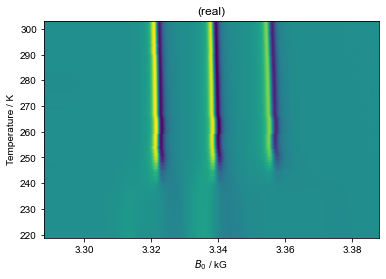

In [84]:
d_cooling = find_file("241206_TS_Isooctane_W20_20mM_run1.DSC", exp_type="francklab_esr/romana") #cooling
d_cooling= d_cooling.chunk_auto('harmonic','harmonic')['harmonic', 0]['phase',0]
d_cooling.reorder('Temperature').sort('Temperature')
d_cooling.pcolor()

I'm having error to plot. Then using chat GPT I found duplicate on data.

In [85]:
temp_values = d_cooling.getaxis('Temperature')
duplicates = temp_values[np.where(np.diff(temp_values) == 0)]
print("1",temp_values)
print("2. Duplicates in Temperature axis:", duplicates)
d_cooling_a = d_cooling["Temperature",0:4]
d_cooling_b = d_cooling["Temperature",5:]
d_cooling = concat([d_cooling_a, d_cooling_b],"Temperature")
# print("3",d_cooling)
temp_values = d_cooling.getaxis('Temperature')
duplicates = temp_values[np.where(np.diff(temp_values) == 0)]
print("4",temp_values)
print("5. Duplicates in Temperature axis:", duplicates)

1 [218.998 219.684 221.676 222.442 222.442 223.164 224.604 225.237 226.207
 227.817 228.39  229.88  230.713 231.018 232.029 234.153 234.373 235.403
 236.991 237.169 238.914 240.096 240.747 241.776 243.961 244.983 244.996
 245.667 247.527 248.129 248.156 249.861 250.22  251.137 252.463 253.866
 254.923 255.595 256.333 258.017 258.292 259.84  260.494 262.259 262.989
 264.304 265.772 265.85  266.095 267.455 269.378 270.803 271.174 272.222
 272.642 273.481 274.103 276.669 277.304 278.778 279.133 279.781 281.367
 282.685 282.964 284.155 285.257 286.004 286.978 288.128 289.315 289.946
 290.274 291.345 292.832 293.121 294.932 295.108 297.041 297.053 299.183
 299.396 300.796 302.133 302.881]
2. Duplicates in Temperature axis: [222.442]
4 [218.998 219.684 221.676 222.442 223.164 224.604 225.237 226.207 227.817
 228.39  229.88  230.713 231.018 232.029 234.153 234.373 235.403 236.991
 237.169 238.914 240.096 240.747 241.776 243.961 244.983 244.996 245.667
 247.527 248.129 248.156 249.861 250.22  

1 [218.998 219.684 221.676 222.442 223.164 224.604 225.237 226.207 227.817
 228.39  229.88  230.713 231.018 232.029 234.153 234.373 235.403 236.991
 237.169 238.914 240.096 240.747 241.776 243.961 244.983 244.996 245.667
 247.527 248.129 248.156 249.861 250.22  251.137 252.463 253.866 254.923
 255.595 256.333 258.017 258.292 259.84  260.494 262.259 262.989 264.304
 265.772 265.85  266.095 267.455 269.378 270.803 271.174 272.222 272.642
 273.481 274.103 276.669 277.304 278.778 279.133 279.781 281.367 282.685
 282.964 284.155 285.257 286.004 286.978 288.128 289.315 289.946 290.274
 291.345 292.832 293.121 294.932 295.108 297.041 297.053 299.183 299.396
 300.796 302.133 302.881]


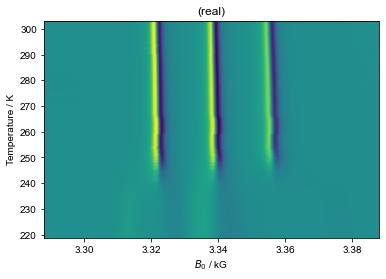

In [87]:
d_cooling.pcolor()
d_cooling.reorder('Temperature').sort('Temperature')
temp_values = d_cooling.getaxis('Temperature')
print("1",temp_values)

In [88]:
print("Dimensions of d_cooling:", d_cooling.dimlabels)

Dimensions of d_cooling: ['Temperature', '$B_0$']


In [29]:
# d_cooling = d_cooling.mean('Temperature')
# # d_cooling.sort('Temperature')
# print("Dimensions of d_cooling:", d_cooling.dimlabels)


Dimensions of d_cooling: ['$B_0$']


## Check field ranges for the three lines

<!-- let's use 300 and 220 K as examples for where the peaks are located in the "high-temp" vs. "low-temp" limits
 -->
<!-- RS: I will set above 260 K and below 260 K -->

## Cooling 

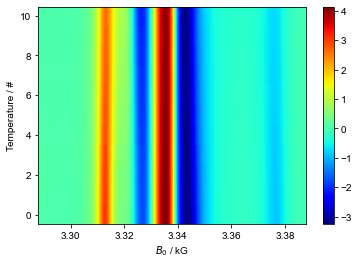

In [80]:
# figure(dpi=300)
d_cooling['Temperature':(200,230)]

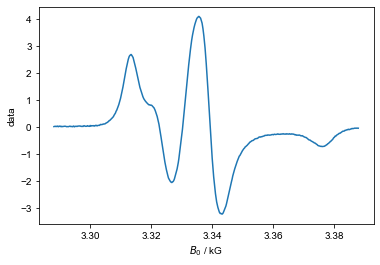

In [13]:
# figure(dpi=300)
d_cooling['Temperature':(229)]

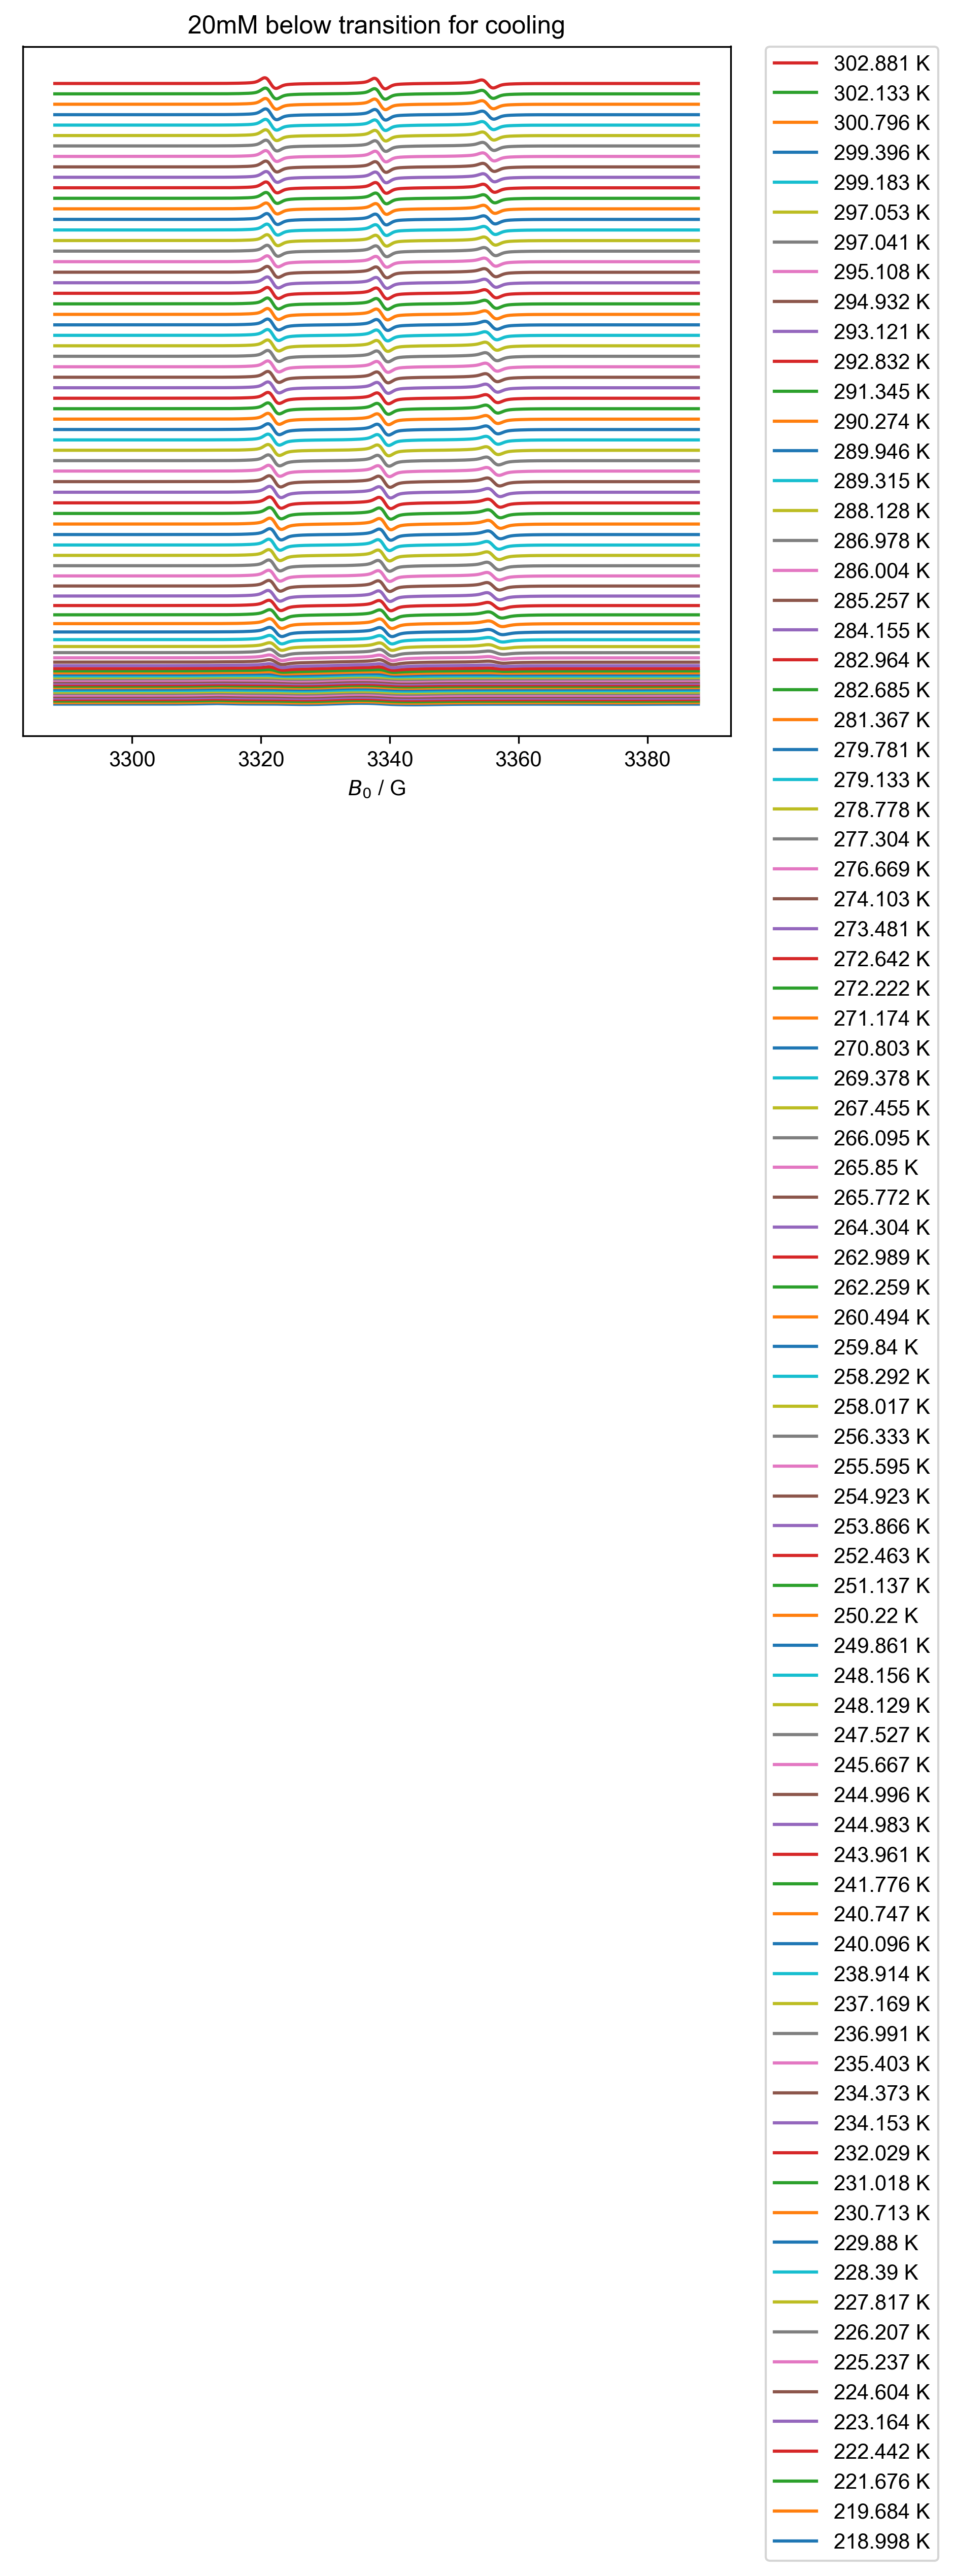

In [81]:
#cooling same plot in offset
offset= 0
d_cooling.sort("Temperature")  # Sort the data along the Temperature axis

for this_label, temp_range in [
    ("20mM below transition for cooling", (200, 350))
 ]:
    this_d1 = d_cooling["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d1.shape["Temperature"]):
        this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d1["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
#         offset += 2.2
        offset += this_d1["Temperature", temp_ithis_dx].max()*1.8
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        # Get handles and labels
        handles, labels = plt.gca().get_legend_handles_labels()
        # Reverse the order of handles and labels
        handles.reverse()
        labels.reverse()
        # Create the legend with reversed order and place it outside of the plot
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)
#     fancy_legend()

In [15]:
# figure(dpi=300)
# d_cooling['Temperature':(None,260)]

RS: For above transition, the fields are

Text(0.5, 1.0, 'peak C')

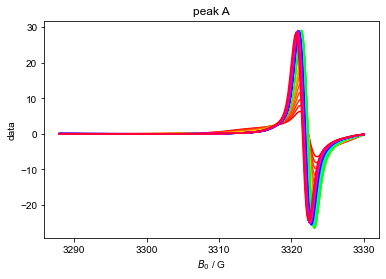

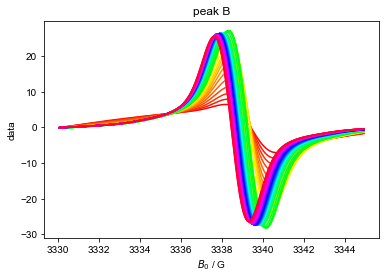

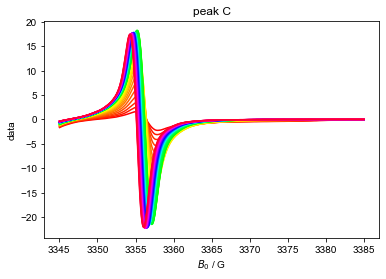

In [96]:
figure()
plot(d_cooling['Temperature':(241,None)]['$B_0$':(3285,3330)]) # peak A above transition
title("peak A")
figure()
plot(d_cooling['Temperature':(241,None)]['$B_0$':(3330,3345)]) # peak B above transition
title("peak B")
figure()
plot(d_cooling['Temperature':(241,None)]['$B_0$':(3345,3385)]) # peak C above transition
title("peak C")

RS: for below transition the fields are

Text(0.5, 1.0, 'peak C')

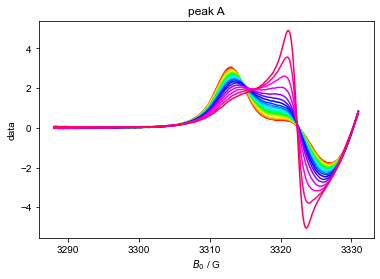

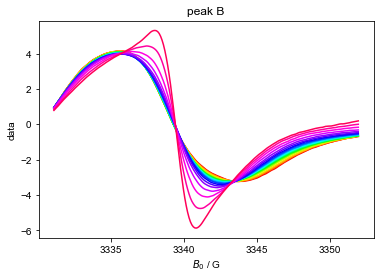

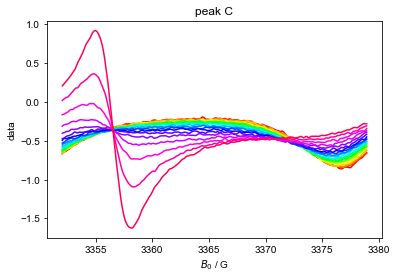

In [102]:
# RS: for below transitions fields 
figure()
plot(d_cooling['Temperature':(None,241)]['$B_0$':(3285,3331)]) # peak A below transition
title("peak A")
figure()
plot(d_cooling['Temperature':(None,241)]['$B_0$':(3331,3352)]) # peak B below transition
title("peak B")
figure()
plot(d_cooling['Temperature':(None,241)]['$B_0$':(3352,3379)]) # peak C below transition
title("peak C")

# # at transition peak C
# figure()
# plot(d_cooling['Temperature':253]['$B_0$':(3386,3403)]) # peak C at transition
# title("peak C at 253 K")

# Pick the Peaks and Calculate the Correlation times

The first cell here only operates over a limited temperature range.

#### RS: All transition 

correlation time is 1.3945023772149409e-08 for temperature 218.998
correlation time is 1.4069352507900256e-08 for temperature 219.684
correlation time is 1.4179370273197985e-08 for temperature 221.676
correlation time is 1.4350784499232217e-08 for temperature 222.442
correlation time is 1.4331317778024221e-08 for temperature 223.164
correlation time is 1.457019454187209e-08 for temperature 224.604
correlation time is 1.4716540129654398e-08 for temperature 225.237
correlation time is 1.4654221574681454e-08 for temperature 226.207
correlation time is 1.4789734956170952e-08 for temperature 227.817
correlation time is 1.55111465946138e-08 for temperature 228.39
correlation time is 1.5516254648364986e-08 for temperature 229.88
correlation time is 1.5611748277560312e-08 for temperature 230.713
correlation time is 1.6400196488917377e-08 for temperature 231.018
correlation time is 1.7072460836552437e-08 for temperature 232.029
correlation time is 1.825207585470022e-08 for temperature 234.153
c

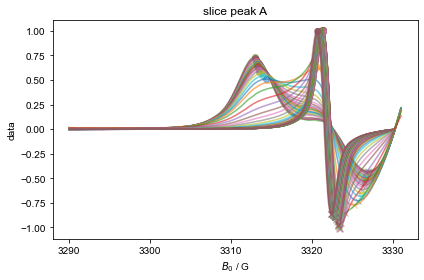

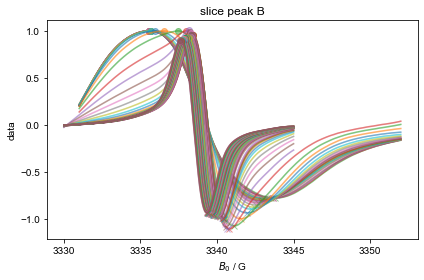

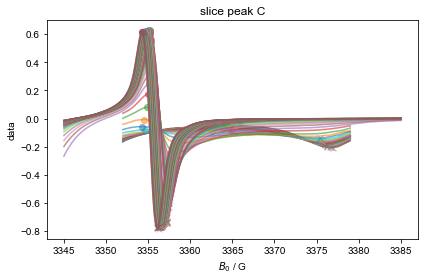

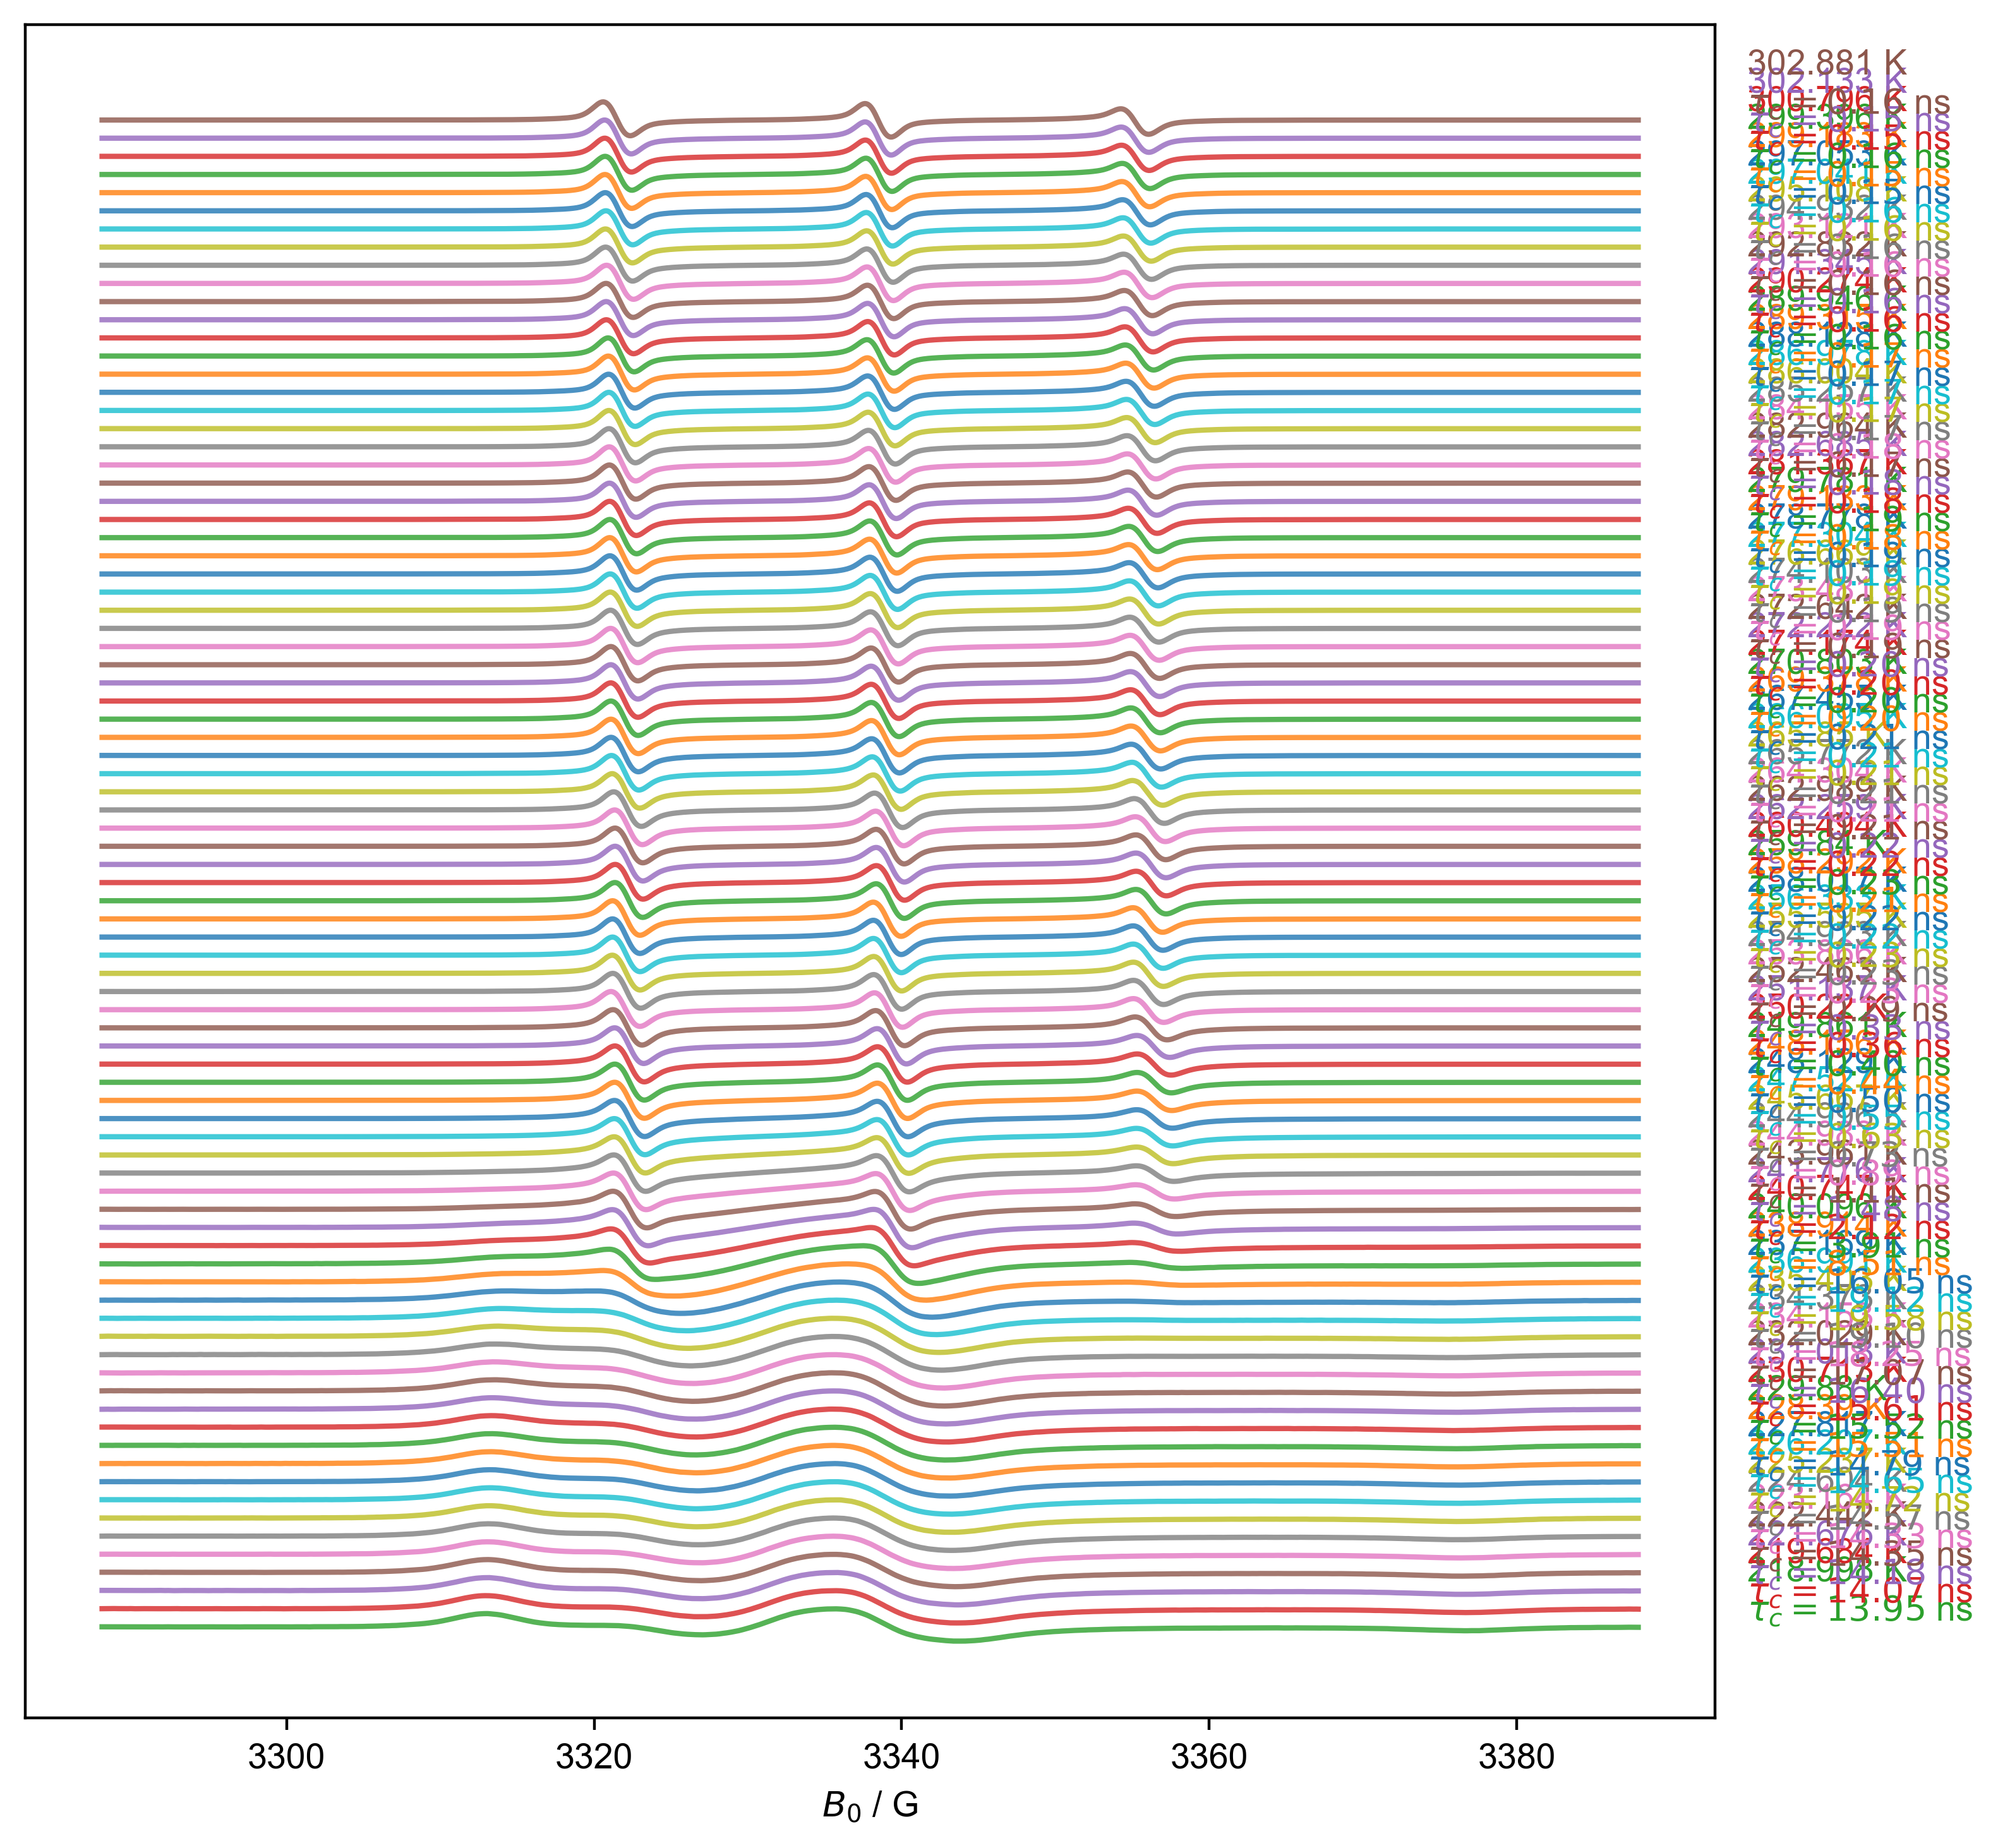

In [107]:
correlation_time_cooling = {}

all_data= d_cooling['Temperature':(None,None)] 
x_counter = 0
j_counter = 0
with figlist_var() as fl: ### why with???
    for this_temp in all_data['Temperature']:
        this_color = next(colors)
        label_str = str(this_temp)
        d = all_data["Temperature": this_temp]
        d /= d.max().item() ### RS item??? normalize??
        peak_data = {}
        # next, we define the ranges for our peaks
        # note that we can replace this with an if ... else statement
        # to allow different peak slices for different temperatures
        if this_temp >= 241:
            peak_A_range = (3290, 3330)
            peak_B_range = (3330, 3345)
            peak_C_range = (3345, 3385)
        else:
            peak_A_range = (3290, 3331)
            peak_B_range = (3331, 3352)
            peak_C_range = (3352, 3379)
        for peak_range,peak_name in [
            (peak_A_range,'A'),
            (peak_B_range,'B'),
            (peak_C_range,'C'),
        ]:
            fl.next(f'slice peak {peak_name}') # move to the figure called "slice peak A", "slice peak B", etc.
            plt.title(fl.current) # this shouldn't be needed -- just says use the current figure name as the title
            peak_spline_fn = d['$B_0$':peak_range].spline_lambda() # create a function that will make a spline curve
            peak = peak_spline_fn(linspace(*tuple(peak_range+(500,)))) # make a smooth, high-res curve of our peak, using the spline
            plot(peak,c=this_color,alpha=0.2)
            peak = d['$B_0$':peak_range].spline_lambda(s_multiplier=1e-4)(linspace(*tuple(peak_range+(500,))))
            plot(peak,c=this_color,alpha=0.5) # overwrite with a smoothed one
            max_B0 = peak.C.argmax().item() # this one returns an nddata, while the argmin returns something that
            #                                 looks like a dictionary
            min_B0 = peak.C.argmin()['$B_0$']  # give the x axis values for the peaks -- there's a bug where
            #                                    this and the previous line should be similar, but are not
            # {{{ here we are builing up a dictionary that has all the values we need to calculate the correlation time
            peak_data[peak_name+'max'] = peak['$B_0$':max_B0].item() # return the y value, and store as value of key Amax, Bmax, Cmax
            peak_data[peak_name+'min'] = peak['$B_0$':min_B0].item()
            peak_data[peak_name+'maxB0'] = max_B0 # set the key AmaxB0, BmaxB0, etc. to max_B0
            peak_data[peak_name+'minB0'] = min_B0
            # }}}
            # {{{ explicitly check that the points that correspond to these values show up in the right place
            plot(peak_data[peak_name+'maxB0'],peak_data[peak_name+'max'],'o',c=this_color,alpha=0.5)
            plot(peak_data[peak_name+'minB0'],peak_data[peak_name+'min'],'x',c=this_color,alpha=0.5)
            # }}}
        fl.next('pub_fig',figsize=(8,12/(1+sqrt(5))*2), dpi=400) ## use golden ratio for figure size
        fl.plot(d+x_counter,alpha=0.8,color=this_color, human_units=False) ### x_counter offsets the curves
        # next, I have a dictionary that contains all the values I need to calculate my correlation time
        # this line plugs those values into the expression for my correlation time:
        # basically, it assumes that all of the words correspond to keys of my dictionary, and it substitutes
        # them with the corresponding values
        tau_c = eval("6.51e-10*(BminB0-BmaxB0)*(sqrt((Bmax-Bmin)/(Amax-Amin))+sqrt((Bmax-Bmin)/(Cmax-Cmin))-2)",{'sqrt':sqrt},peak_data)
        # above is equivalent to: 6.51e-10*(peak_data['BminB0']-peak_data['BmaxB0']*(sqrt((...
        print("correlation time is",tau_c, "for temperature", this_temp)
        correlation_time_cooling[label_str] = tau_c 
        plt.gca().text(
                3395,
                x_counter,
                label_str+f' K\n$\\tau_c={tau_c/1e-9:0.2f}$ ns',
                transform=plt.gca().transData,
                va='bottom',
                ha='left',
                color=this_color,
                )
        x_counter += 1
        #xlim(3375,3550)
        j_counter += 1.1
    fl.next('pub_fig')
    plt.title('')
    plt.ylabel('')
    plt.gca().tick_params(left=False, bottom=True, right=False, top=False,
                          labelleft=False, labelbottom=True,
                          labelright=False)

In [108]:
correlation_time_cooling

{'218.998': 1.3945023772149409e-08,
 '219.684': 1.4069352507900256e-08,
 '221.676': 1.4179370273197985e-08,
 '222.442': 1.4350784499232217e-08,
 '223.164': 1.4331317778024221e-08,
 '224.604': 1.457019454187209e-08,
 '225.237': 1.4716540129654398e-08,
 '226.207': 1.4654221574681454e-08,
 '227.817': 1.4789734956170952e-08,
 '228.39': 1.55111465946138e-08,
 '229.88': 1.5516254648364986e-08,
 '230.713': 1.5611748277560312e-08,
 '231.018': 1.6400196488917377e-08,
 '232.029': 1.7072460836552437e-08,
 '234.153': 1.825207585470022e-08,
 '234.373': 1.9095441269488536e-08,
 '235.403': 1.9584224280397403e-08,
 '236.991': 1.9118567675640322e-08,
 '237.169': 1.604511462650694e-08,
 '238.914': 8.505204501381163e-09,
 '240.096': 3.906568478302326e-09,
 '240.747': 2.1174027190197813e-09,
 '241.776': 1.4820199597197126e-09,
 '243.961': 1.106038363999954e-09,
 '244.983': 8.93563255495762e-10,
 '244.996': 7.312639694800766e-10,
 '245.667': 6.293635017202297e-10,
 '247.527': 5.494478320560237e-10,
 '248.1

In [109]:
temp_cooling= np.array([float(j) for j in correlation_time_cooling.keys()])
tau_cooling = np.array(list(correlation_time_cooling.values()))

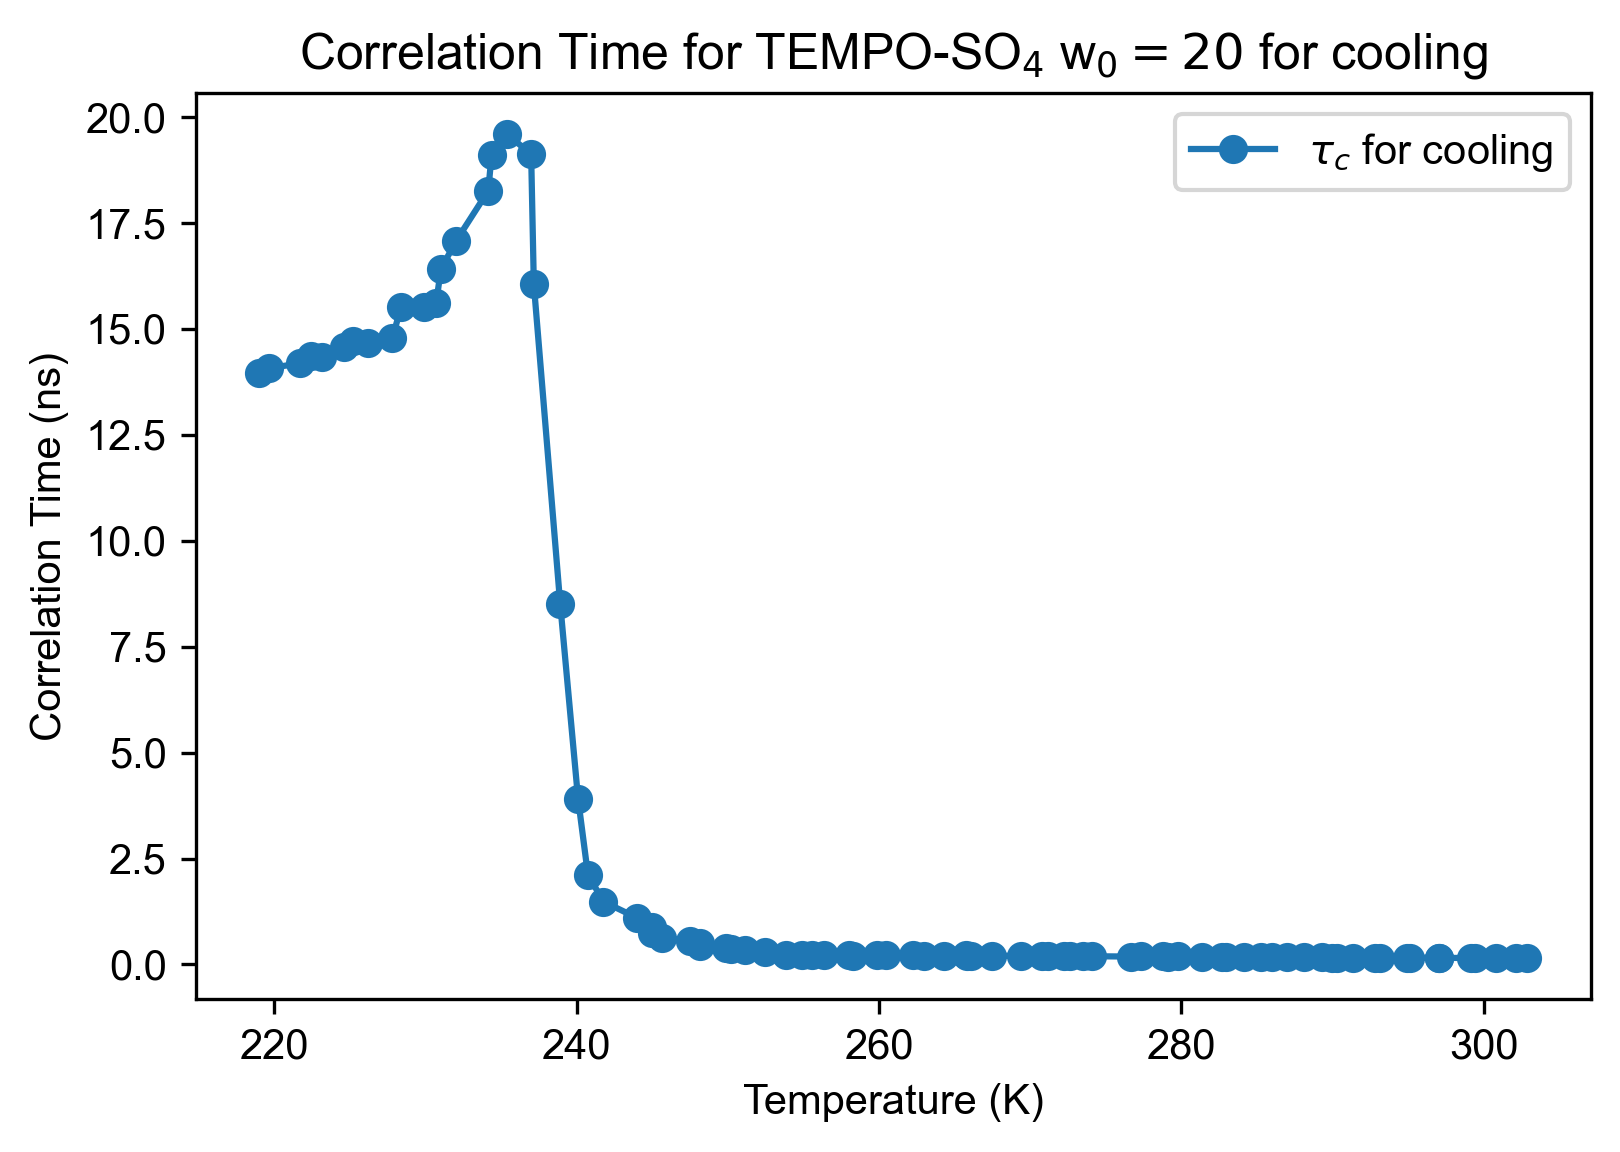

In [110]:
# Tau caculation
figure(dpi=300, figsize=(6,4))
plot(temp_cooling, tau_cooling/1e-9, linestyle='-',  marker='o', label=r"$\tau_c$ for cooling")
legend()
# xlim(253,335)
xlabel('Temperature (K)')
ylabel('Correlation Time (ns)')
title('Correlation Time for TEMPO-SO$_4$ w$_0=20$ for cooling')
show()

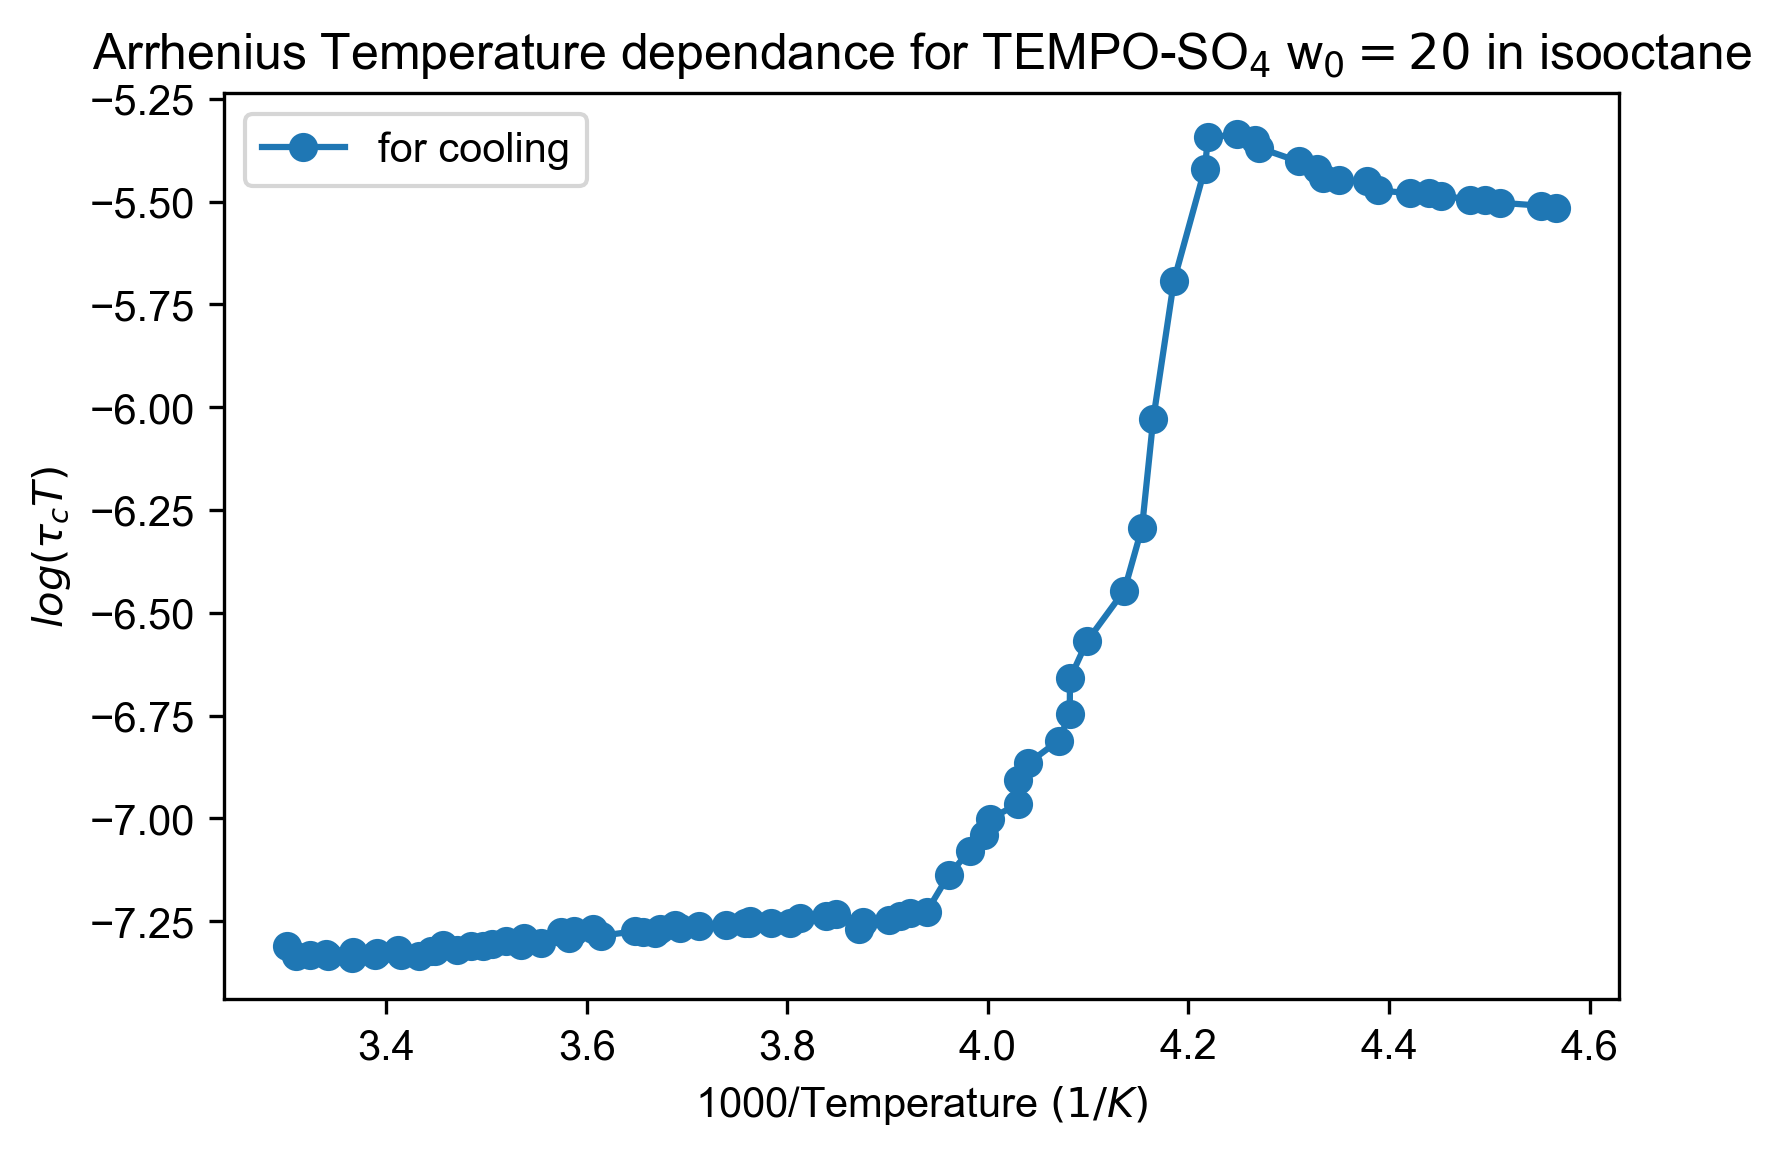

In [111]:
# Arrhenius  
figure(dpi=300, figsize=(6,4))
plot(1000/temp_cooling, log10(tau_cooling*temp_cooling), linestyle='-',  marker='o', label=r"for cooling")
legend()
xlabel(r"1000/Temperature $(1/K)$")
ylabel(r"$log(\tau_cT)$")
title('Arrhenius Temperature dependance for TEMPO-SO$_4$ w$_0=20$ in isooctane')
show()

<!-- #### RS: Below transition  -->

<!-- all_data= d_cooling['Temperature':(None,260)] # let's start just with high temp
x_counter = 0
j_counter = 0
correlation_time_below={}
with figlist_var() as fl: ### why with???
    for this_temp in all_data['Temperature']:
        this_color = next(colors)
        label_str = str(this_temp)
        d = all_data["Temperature": this_temp]
        d /= d.max().item() ### RS item??? normalize??
        peak_data = {}
        # next, we define the ranges for our peaks
        # note that we can replace this with an if ... else statement
        # to allow different peak slices for different temperatures
        if this_temp >= 260:
            peak_A_range = (3340,3360)
            peak_B_range = (3360,3375)
            peak_C_range = (3375,3395)
        elif this_temp >= 253:
            peak_A_range = (3320,3358)
            peak_B_range = (3358,3382)
            peak_C_range = (3387,3404)
        else:
            peak_A_range = (3320,3358)
            peak_B_range = (3358,3382)
            peak_C_range = (3382,3406)
        for peak_range,peak_name in [
            (peak_A_range,'A'),
            (peak_B_range,'B'),
            (peak_C_range,'C'),
        ]:
            fl.next(f'slice peak {peak_name}') # move to the figure called "slice peak A", "slice peak B", etc.
            plt.title(fl.current) # this shouldn't be needed -- just says use the current figure name as the title
            peak_spline_fn = d['$B_0$':peak_range].spline_lambda() # create a function that will make a spline curve
            peak = peak_spline_fn(linspace(*tuple(peak_range+(500,)))) # make a smooth, high-res curve of our peak, using the spline
            plot(peak,c=this_color,alpha=0.2)
            peak = d['$B_0$':peak_range].spline_lambda(s_multiplier=2e-4)(linspace(*tuple(peak_range+(500,))))
            plot(peak,c=this_color,alpha=0.5) # overwrite with a smoothed one
            max_B0 = peak.C.argmax().item() # this one returns an nddata, while the argmin returns something that
            #                                 looks like a dictionary
            min_B0 = peak.C.argmin()['$B_0$']  # give the x axis values for the peaks -- there's a bug where
            #                                    this and the previous line should be similar, but are not
            # {{{ here we are builing up a dictionary that has all the values we need to calculate the correlation time
            peak_data[peak_name+'max'] = peak['$B_0$':max_B0].item() # return the y value, and store as value of key Amax, Bmax, Cmax
            peak_data[peak_name+'min'] = peak['$B_0$':min_B0].item()
            peak_data[peak_name+'maxB0'] = max_B0 # set the key AmaxB0, BmaxB0, etc. to max_B0
            peak_data[peak_name+'minB0'] = min_B0
            # }}}
            # {{{ explicitly check that the points that correspond to these values show up in the right place
            plot(peak_data[peak_name+'maxB0'],peak_data[peak_name+'max'],'o',c=this_color,alpha=0.5)
            plot(peak_data[peak_name+'minB0'],peak_data[peak_name+'min'],'x',c=this_color,alpha=0.5)
            # }}}
        fl.next('pub_fig',figsize=(10,10/(1+sqrt(5))*2), dpi=400) ## use golden ratio for figure size
        fl.plot(d+x_counter,alpha=0.8,color=this_color, human_units=False) ### x_counter offsets the curves
        # next, I have a dictionary that contains all the values I need to calculate my correlation time
        # this line plugs those values into the expression for my correlation time:
        # basically, it assumes that all of the words correspond to keys of my dictionary, and it substitutes
        # them with the corresponding values
        tau_c = eval("6.51e-10*(BminB0-BmaxB0)*(sqrt((Bmax-Bmin)/(Amax-Amin))+sqrt((Bmax-Bmin)/(Cmax-Cmin))-2)",{'sqrt':sqrt},peak_data)
        # above is equivalent to: 6.51e-10*(peak_data['BminB0']-peak_data['BmaxB0']*(sqrt((...
        print("correlation time is",tau_c)
        correlation_time_below[label_str] = tau_c 
        plt.gca().text(
                3385,
                x_counter,
                label_str+f' K\n$\\tau_c={tau_c/1e-9:0.1f}$ ns',
                transform=plt.gca().transData,
                va='bottom',
                ha='left',
                color=this_color,
                )
        x_counter += 1.5
        #xlim(3375,3550)
        j_counter += 1
    fl.next('pub_fig')
    plt.title('below transition for cooling TEMPO-SO$_4$ w$_0=20$ in isooctane')
    plt.ylabel('')
    plt.gca().tick_params(left=False, bottom=True, right=False, top=False,
                          labelleft=False, labelbottom=True,
                          labelright=False) -->

<!-- # correlation_time_below -->

<!-- # temp= [float(temp) for temp in correlation_time_below.keys()]
# tau_below= list(correlation_time_below.values())
# figure(dpi=300, figsize=(8,6))
# tau_ns_below = [t / 1e-9 for t in tau_below]
# plot(temp, tau_ns_below, linestyle='-',  marker='o', label=r"$\tau_c$")
# legend()
# xlabel('Temperature (K)')
# ylabel('Correlation Time (ns)')
# title('Correlation Time for TEMPO-SO$_4$ w$_0=20$')
# show() -->

## Reheating 

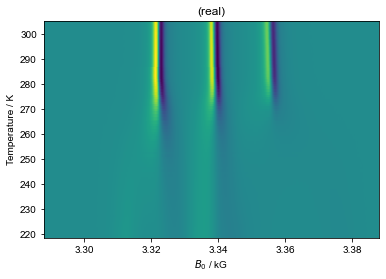

In [112]:
d_reheating = find_file("241206_TS_Isooctane_W20_20mM_run2.DSC", exp_type="francklab_esr/romana") #reheating subsequently
d_reheating= d_reheating.chunk_auto('harmonic','harmonic')['harmonic', 0]['phase',0]
d_reheating.reorder('Temperature').sort('Temperature')
d_reheating.pcolor()

In [118]:
temp_values = d_reheating.getaxis('Temperature')
duplicates = temp_values[np.where(np.diff(temp_values) == 0)]
print("1",temp_values)
print("2. Duplicates in Temperature axis:", duplicates)
d_reheating_a = d_reheating["Temperature",0:13]
d_reheating_b = d_reheating["Temperature",14:]
d_reheating = concat([d_reheating_a, d_reheating_b],"Temperature")
# print("3",d_cooling)
temp_values = d_reheating.getaxis('Temperature')
duplicates = temp_values[np.where(np.diff(temp_values) == 0)]
print("4",temp_values)
print("5. Duplicates in Temperature axis:", duplicates)

1 [218.998 220.226 221.279 222.244 223.249 224.308 225.139 226.249 227.105
 227.986 228.795 230.493 232.707 232.707 234.746 234.952 236.158 237.034
 238.806 238.875 239.88  241.885 241.939 243.68  243.828 245.776 245.937
 247.743 247.944 249.837 249.89  251.869 251.936 253.816 254.225 254.925
 256.796 257.125 258.925 258.99  260.785 260.942 262.718 263.239 264.762
 265.243 265.892 267.756 268.053 269.856 270.165 271.919 271.932 273.599
 274.526 275.097 275.961 277.676 278.197 279.848 279.987 281.561 281.865
 283.754 283.855 285.932 286.375 287.084 287.475 288.512 289.774 291.023
 291.855 292.926 293.945 295.126 295.516 297.085 297.736 298.313 300.353
 300.653 301.54  303.985]
2. Duplicates in Temperature axis: [232.707]
4 [218.998 220.226 221.279 222.244 223.249 224.308 225.139 226.249 227.105
 227.986 228.795 230.493 232.707 234.746 234.952 236.158 237.034 238.806
 238.875 239.88  241.885 241.939 243.68  243.828 245.776 245.937 247.743
 247.944 249.837 249.89  251.869 251.936 253.816 

1 [218.998 220.226 221.279 222.244 223.249 224.308 225.139 226.249 227.105
 227.986 228.795 230.493 232.707 234.746 234.952 236.158 237.034 238.806
 238.875 239.88  241.885 241.939 243.68  243.828 245.776 245.937 247.743
 247.944 249.837 249.89  251.869 251.936 253.816 254.225 254.925 256.796
 257.125 258.925 258.99  260.785 260.942 262.718 263.239 264.762 265.243
 265.892 267.756 268.053 269.856 270.165 271.919 271.932 273.599 274.526
 275.097 275.961 277.676 278.197 279.848 279.987 281.561 281.865 283.754
 283.855 285.932 286.375 287.084 287.475 288.512 289.774 291.023 291.855
 292.926 293.945 295.126 295.516 297.085 297.736 298.313 300.353 300.653
 301.54  303.985]


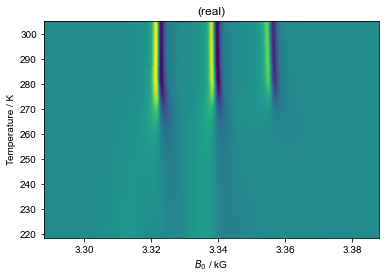

In [119]:
d_reheating.pcolor()
d_reheating.reorder('Temperature').sort('Temperature')
temp_values = d_reheating.getaxis('Temperature')
print("1",temp_values)

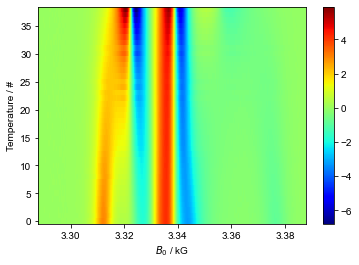

In [133]:
figure()
d_reheating['Temperature':(None,260)]

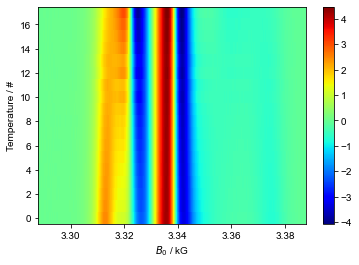

In [134]:
figure()
d_reheating['Temperature':(232,250)]

Text(0.5, 1.0, 'peak C')

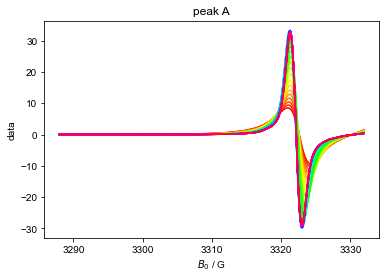

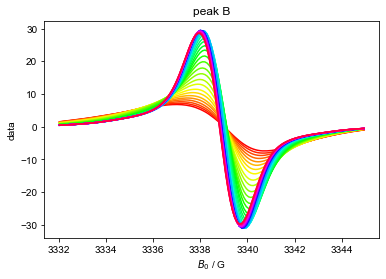

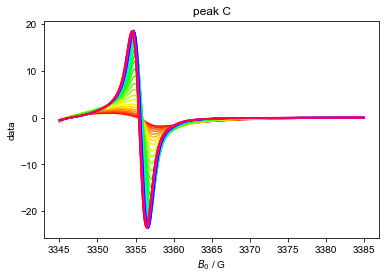

In [122]:
# RS: Above transition fields
figure()
plot(d_reheating['Temperature':(263,None)]['$B_0$':(3285,3332)]) # peak A above transition
title("peak A")
figure()
plot(d_reheating['Temperature':(263,None)]['$B_0$':(3332,3345)]) # peak B above transition
title("peak B")
figure()
plot(d_reheating['Temperature':(263,None)]['$B_0$':(3345,3385)]) # peak C above transition
title("peak C")

Text(0.5, 1.0, 'peak C')

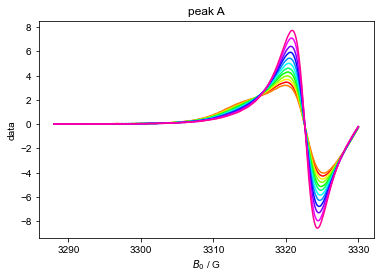

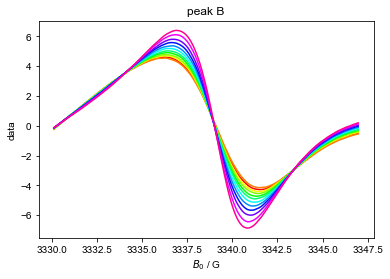

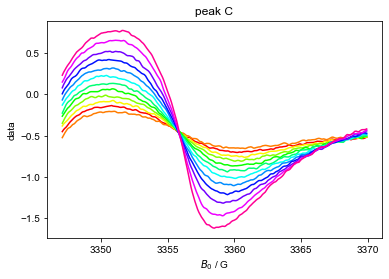

In [154]:
# RS: Intermediate transition fields
figure()
plot(d_reheating['Temperature':(250,263)]['$B_0$':(3285,3330)]) # peak A above transition
title("peak A")
figure()
plot(d_reheating['Temperature':(250,263)]['$B_0$':(3330,3347)]) # peak B above transition
title("peak B")
figure()
plot(d_reheating['Temperature':(250,263)]['$B_0$':(3347,3370)]) # peak C above transition
title("peak C")

Text(0.5, 1.0, 'peak C')

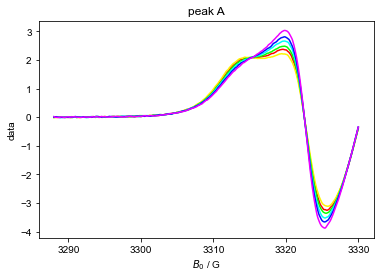

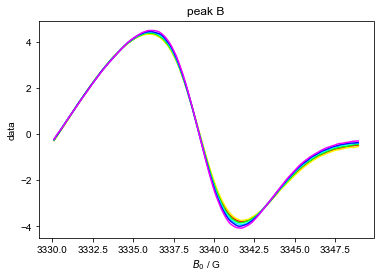

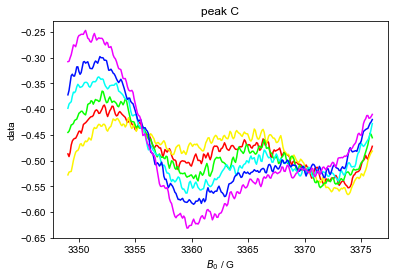

In [155]:
# RS: Intermediate 2 transition fields
figure()
plot(d_reheating['Temperature':(245,250)]['$B_0$':(3285,3330)]) # peak A above transition
title("peak A")
figure()
plot(d_reheating['Temperature':(245,250)]['$B_0$':(3330,3349)]) # peak B above transition
title("peak B")
figure()
plot(d_reheating['Temperature':(245,250)]['$B_0$':(3349,3376)]) # peak C above transition
title("peak C")

Text(0.5, 1.0, 'peak C')

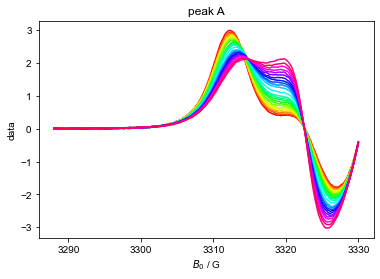

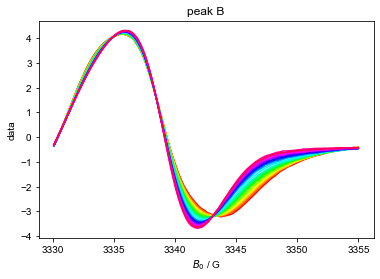

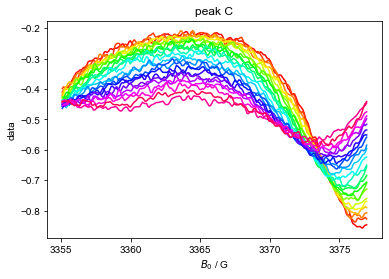

In [157]:
# RS: Below transition fields
figure()
plot(d_reheating['Temperature':(None,245)]['$B_0$':(3285,3330)]) # peak A above transition
title("peak A")
figure()
plot(d_reheating['Temperature':(None,245)]['$B_0$':(3330,3355)]) # peak B above transition
title("peak B")
figure()
plot(d_reheating['Temperature':(None,245)]['$B_0$':(3355,3377)]) # peak C above transition
title("peak C")

#### RS: All transition

correlation time is 1.6138620745640144e-10
correlation time is 1.6138620745640144e-10
correlation time is 1.6138620745640144e-10
correlation time is 1.6138620745640144e-10
correlation time is 1.6138620745640144e-10
correlation time is 1.6138620745640144e-10
correlation time is 1.6138620745640144e-10
correlation time is 1.6138620745640144e-10
correlation time is 1.6138620745640144e-10
correlation time is 1.6138620745640144e-10
correlation time is 1.6138620745640144e-10
correlation time is 1.6138620745640144e-10
correlation time is 1.6138620745640144e-10
correlation time is 1.6138620745640144e-10
correlation time is 1.6138620745640144e-10
correlation time is 1.6138620745640144e-10
correlation time is 1.6138620745640144e-10
correlation time is 1.6138620745640144e-10
correlation time is 1.6138620745640144e-10
correlation time is 1.6138620745640144e-10
correlation time is 1.6138620745640144e-10
correlation time is 1.6138620745640144e-10
correlation time is 1.6138620745640144e-10
correlation

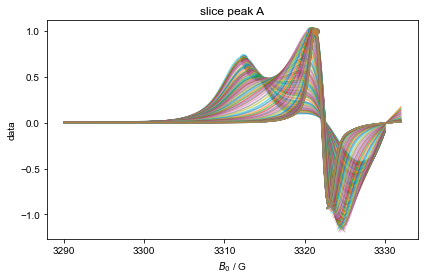

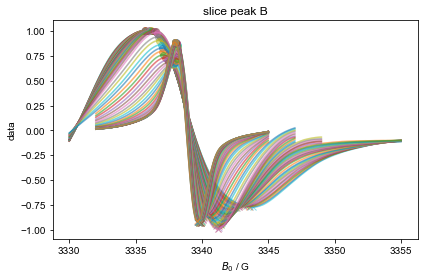

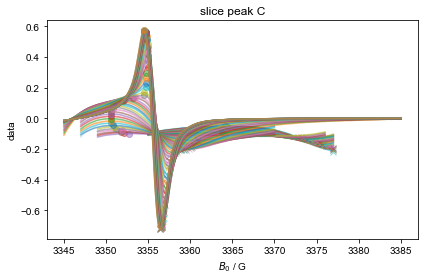

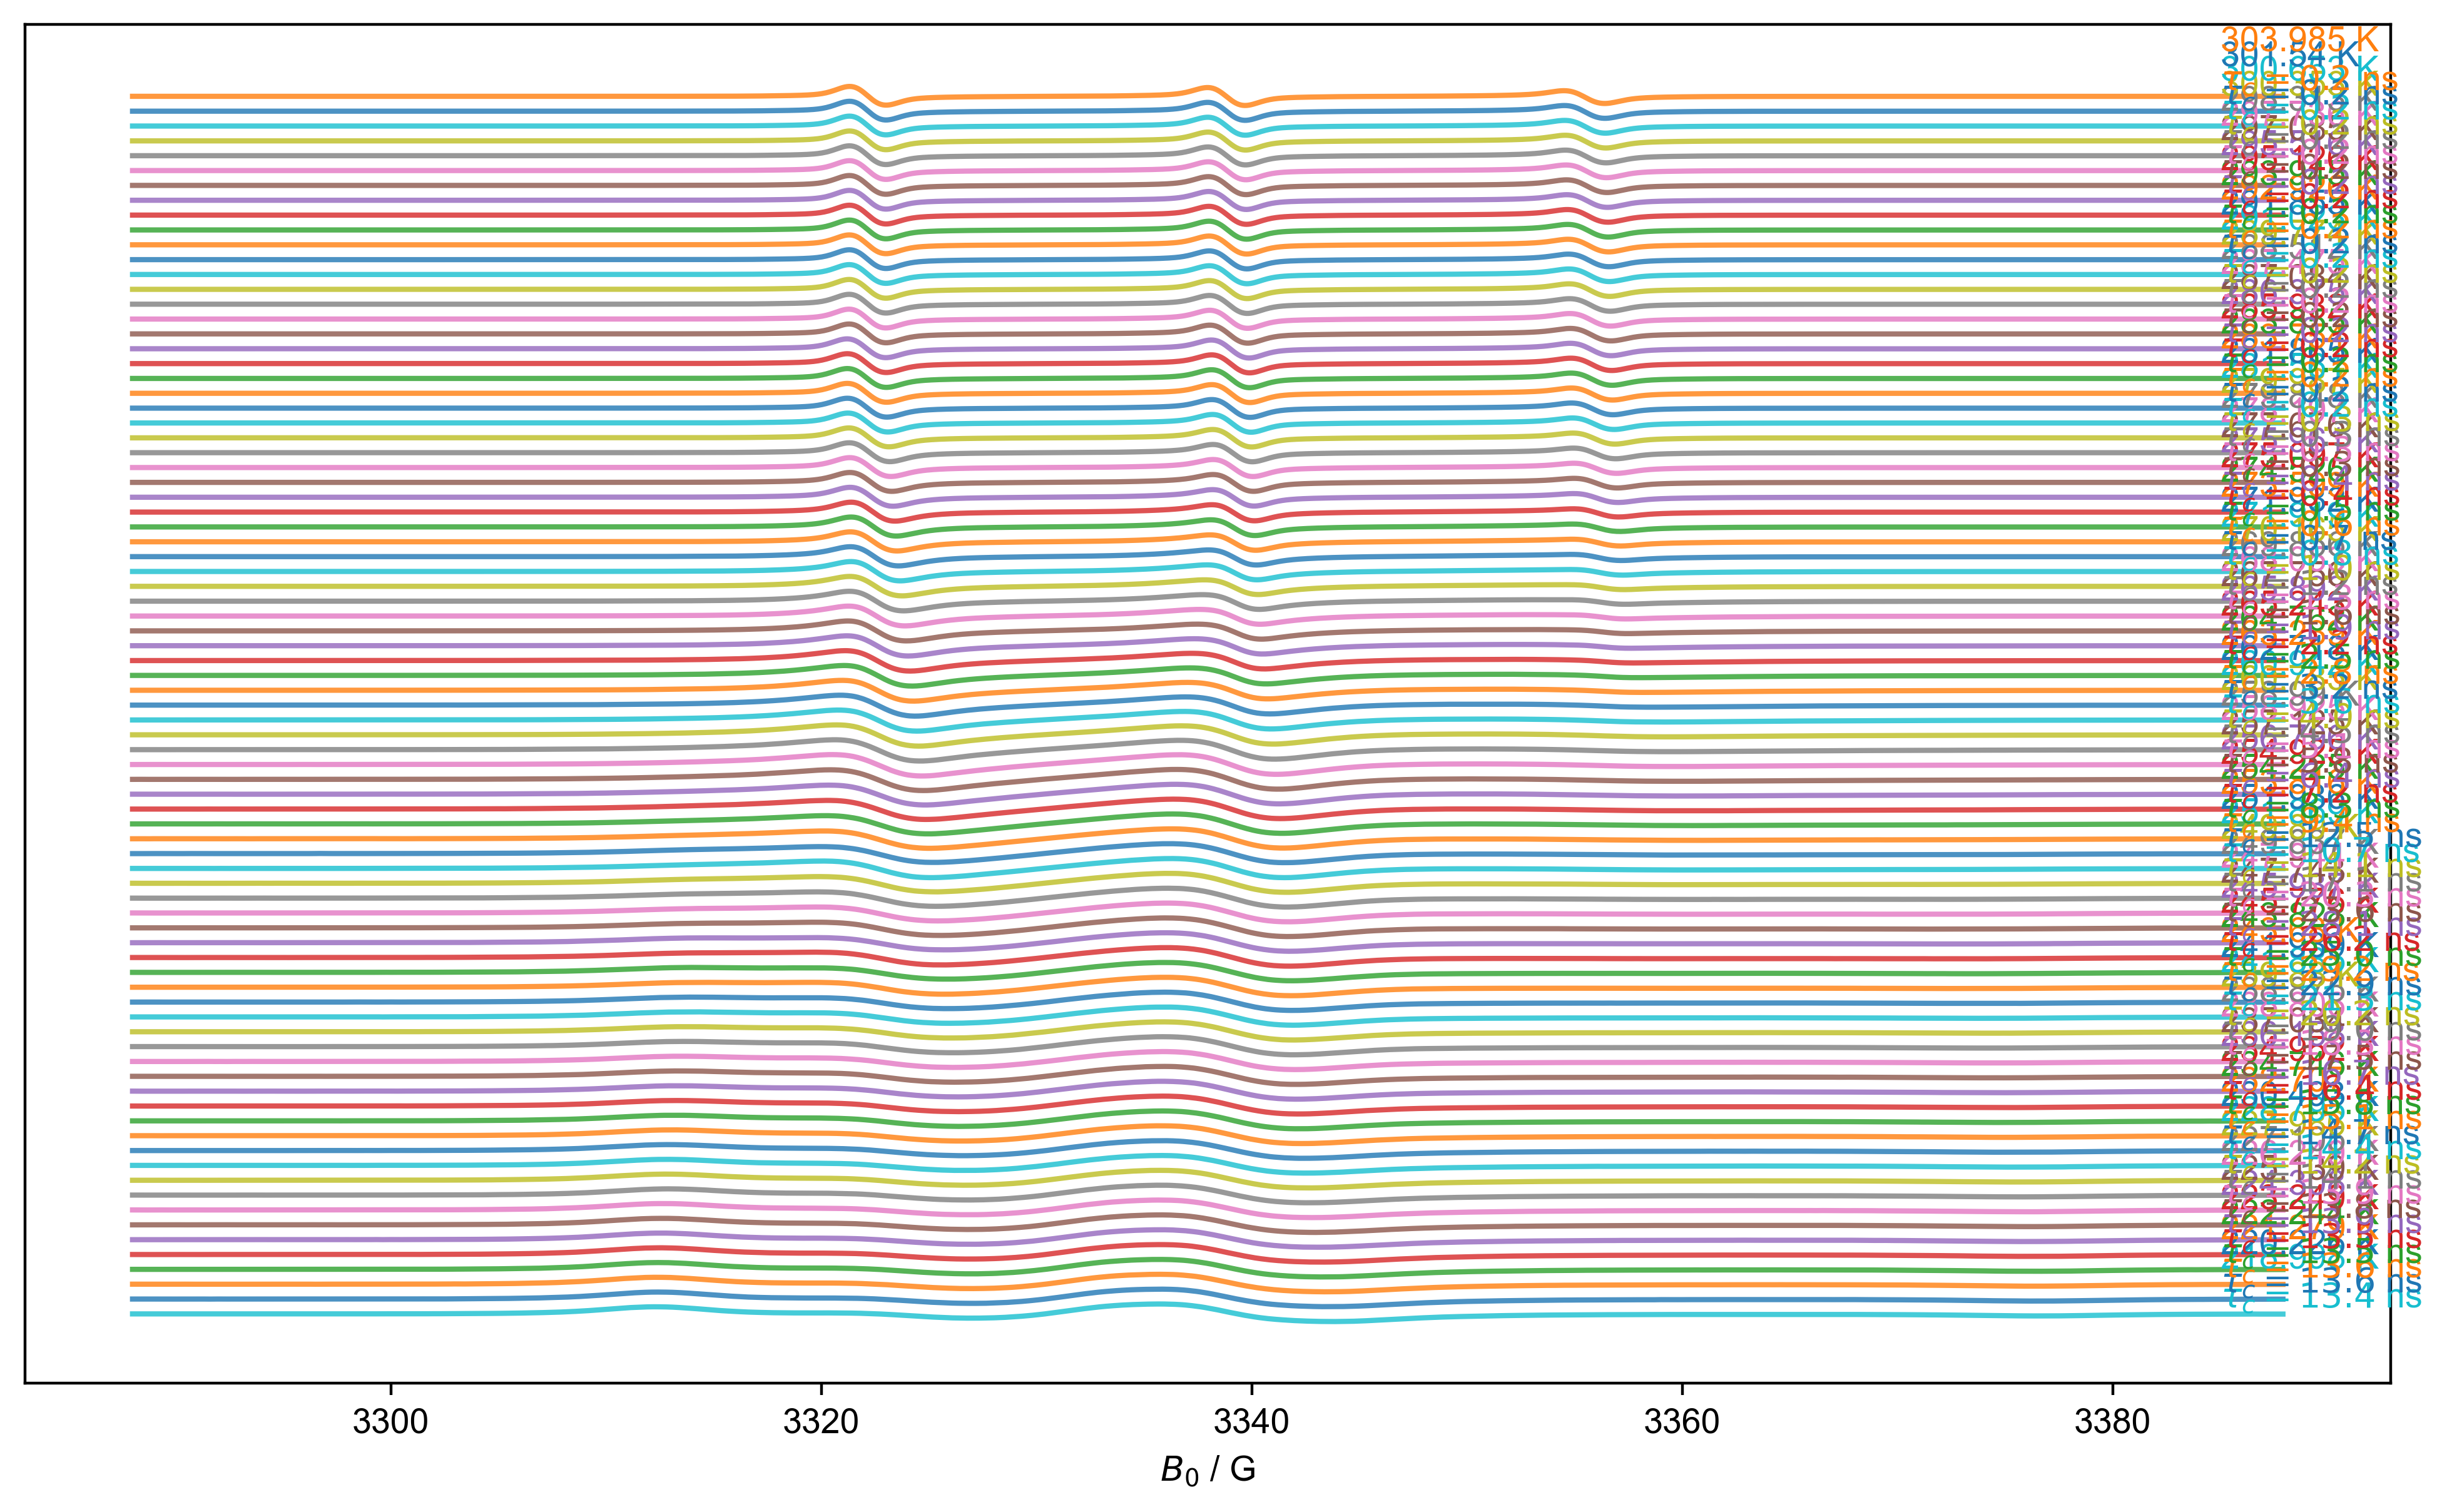

In [163]:
correlation_time_reheating = {}

all_data_reheating= d_reheating['Temperature':(None,None)] # let's start just with high temp
x_counter = 0
j_counter = 0
with figlist_var() as fl: ### why with???
    for this_temp in all_data_reheating['Temperature']:
        this_color = next(colors)
        label_str = str(this_temp)
        d = all_data_reheating["Temperature": this_temp]
        d /= d.max().item() ### RS item??? normalize??
        peak_data_reheating = {}
        # next, we define the ranges for our peaks
        # note that we can replace this with an if ... else statement
        # to allow different peak slices for different temperatures
        if this_temp >= 263:
            peak_A_range = (3290,3332)
            peak_B_range = (3332,3345)
            peak_C_range = (3345,3385)
        elif this_temp >= 250:
            peak_A_range = (3290,3330)
            peak_B_range = (3330,3347)
            peak_C_range = (3347,3370)
        elif this_temp >= 245:
            peak_A_range = (3290,3330)
            peak_B_range = (3330,3349)
            peak_C_range = (3349,3376)
        else:
            peak_A_range = (3290,3330)
            peak_B_range = (3330,3355)
            peak_C_range = (3355,3377)
        for peak_range,peak_name in [
            (peak_A_range,'A'),
            (peak_B_range,'B'),
            (peak_C_range,'C'),
        ]:
            fl.next(f'slice peak {peak_name}') # move to the figure called "slice peak A", "slice peak B", etc.
            plt.title(fl.current) # this shouldn't be needed -- just says use the current figure name as the title
            peak_spline_fn = d['$B_0$':peak_range].spline_lambda() # create a function that will make a spline curve
            peak = peak_spline_fn(linspace(*tuple(peak_range+(500,)))) # make a smooth, high-res curve of our peak, using the spline
            plot(peak,c=this_color,alpha=0.2)
            peak = d['$B_0$':peak_range].spline_lambda(s_multiplier=3e-4)(linspace(*tuple(peak_range+(500,))))
            plot(peak,c=this_color,alpha=0.5) # overwrite with a smoothed one
            max_B0 = peak.C.argmax().item() # this one returns an nddata, while the argmin returns something that
            #                                 looks like a dictionary
            min_B0 = peak.C.argmin()['$B_0$']  # give the x axis values for the peaks -- there's a bug where
            #                                    this and the previous line should be similar, but are not
            # {{{ here we are builing up a dictionary that has all the values we need to calculate the correlation time
            peak_data_reheating[peak_name+'max'] = peak['$B_0$':max_B0].item() # return the y value, and store as value of key Amax, Bmax, Cmax
            peak_data_reheating[peak_name+'min'] = peak['$B_0$':min_B0].item()
            peak_data_reheating[peak_name+'maxB0'] = max_B0 # set the key AmaxB0, BmaxB0, etc. to max_B0
            peak_data_reheating[peak_name+'minB0'] = min_B0
            # }}}
            # {{{ explicitly check that the points that correspond to these values show up in the right place
            plot(peak_data_reheating[peak_name+'maxB0'],peak_data_reheating[peak_name+'max'],'o',c=this_color,alpha=0.5)
            plot(peak_data_reheating[peak_name+'minB0'],peak_data_reheating[peak_name+'min'],'x',c=this_color,alpha=0.5)
            # }}}
        fl.next('pub_fig',figsize=(10,10/(1+sqrt(5))*2), dpi=400) ## use golden ratio for figure size
        fl.plot(d+x_counter,alpha=0.8,color=this_color, human_units=False) ### x_counter offsets the curves
        # next, I have a dictionary that contains all the values I need to calculate my correlation time
        # this line plugs those values into the expression for my correlation time:
        # basically, it assumes that all of the words correspond to keys of my dictionary, and it substitutes
        # them with the corresponding values
        tau_c_reheating = eval("6.51e-10*(BminB0-BmaxB0)*(sqrt((Bmax-Bmin)/(Amax-Amin))+sqrt((Bmax-Bmin)/(Cmax-Cmin))-2)",{'sqrt':sqrt},peak_data_reheating)
        # above is equivalent to: 6.51e-10*(peak_data['BminB0']-peak_data['BmaxB0']*(sqrt((...
        print("correlation time is",tau_c)
        correlation_time_reheating[label_str] = tau_c_reheating 
        plt.gca().text(
                3385,
                x_counter,
                label_str+f' K\n$\\tau_c={tau_c_reheating/1e-9:0.1f}$ ns',
                transform=plt.gca().transData,
                va='bottom',
                ha='left',
                color=this_color,
                )
        x_counter += 1.5
        #xlim(3375,3550)
        j_counter += 1
    fl.next('pub_fig')
    plt.title('')
    plt.ylabel('')
    plt.gca().tick_params(left=False, bottom=True, right=False, top=False,
                          labelleft=False, labelbottom=True,
                          labelright=False)

In [164]:
correlation_time_reheating

{'218.998': 1.3399739212523675e-08,
 '220.226': 1.3619992605908108e-08,
 '221.279': 1.3617230855932697e-08,
 '222.244': 1.3509784241737273e-08,
 '223.249': 1.34862064014223e-08,
 '224.308': 1.387626910294885e-08,
 '225.139': 1.3815780185073507e-08,
 '226.249': 1.3947780118169991e-08,
 '227.105': 1.4080012285943794e-08,
 '227.986': 1.4240424967652353e-08,
 '228.795': 1.441235152225066e-08,
 '230.493': 1.4661533409157785e-08,
 '232.707': 1.513222994265143e-08,
 '234.746': 1.5832035254002586e-08,
 '234.952': 1.635153893414053e-08,
 '236.158': 1.670319627016694e-08,
 '237.034': 1.7526634411830567e-08,
 '238.806': 1.8280870140065757e-08,
 '238.875': 1.9022857545720456e-08,
 '239.88': 2.0157323714126053e-08,
 '241.885': 2.1334753855356488e-08,
 '241.939': 2.2900597555849577e-08,
 '243.68': 2.9192002842426486e-08,
 '243.828': 2.5026432820578405e-08,
 '245.776': 2.6180194931132148e-08,
 '245.937': 2.8127947889613785e-08,
 '247.743': 2.3609339815226124e-08,
 '247.944': 2.0329406886882426e-08,
 

In [165]:
temp_reheating= np.array([float(j) for j in correlation_time_reheating.keys()])
tau_reheating = np.array(list(correlation_time_reheating.values()))

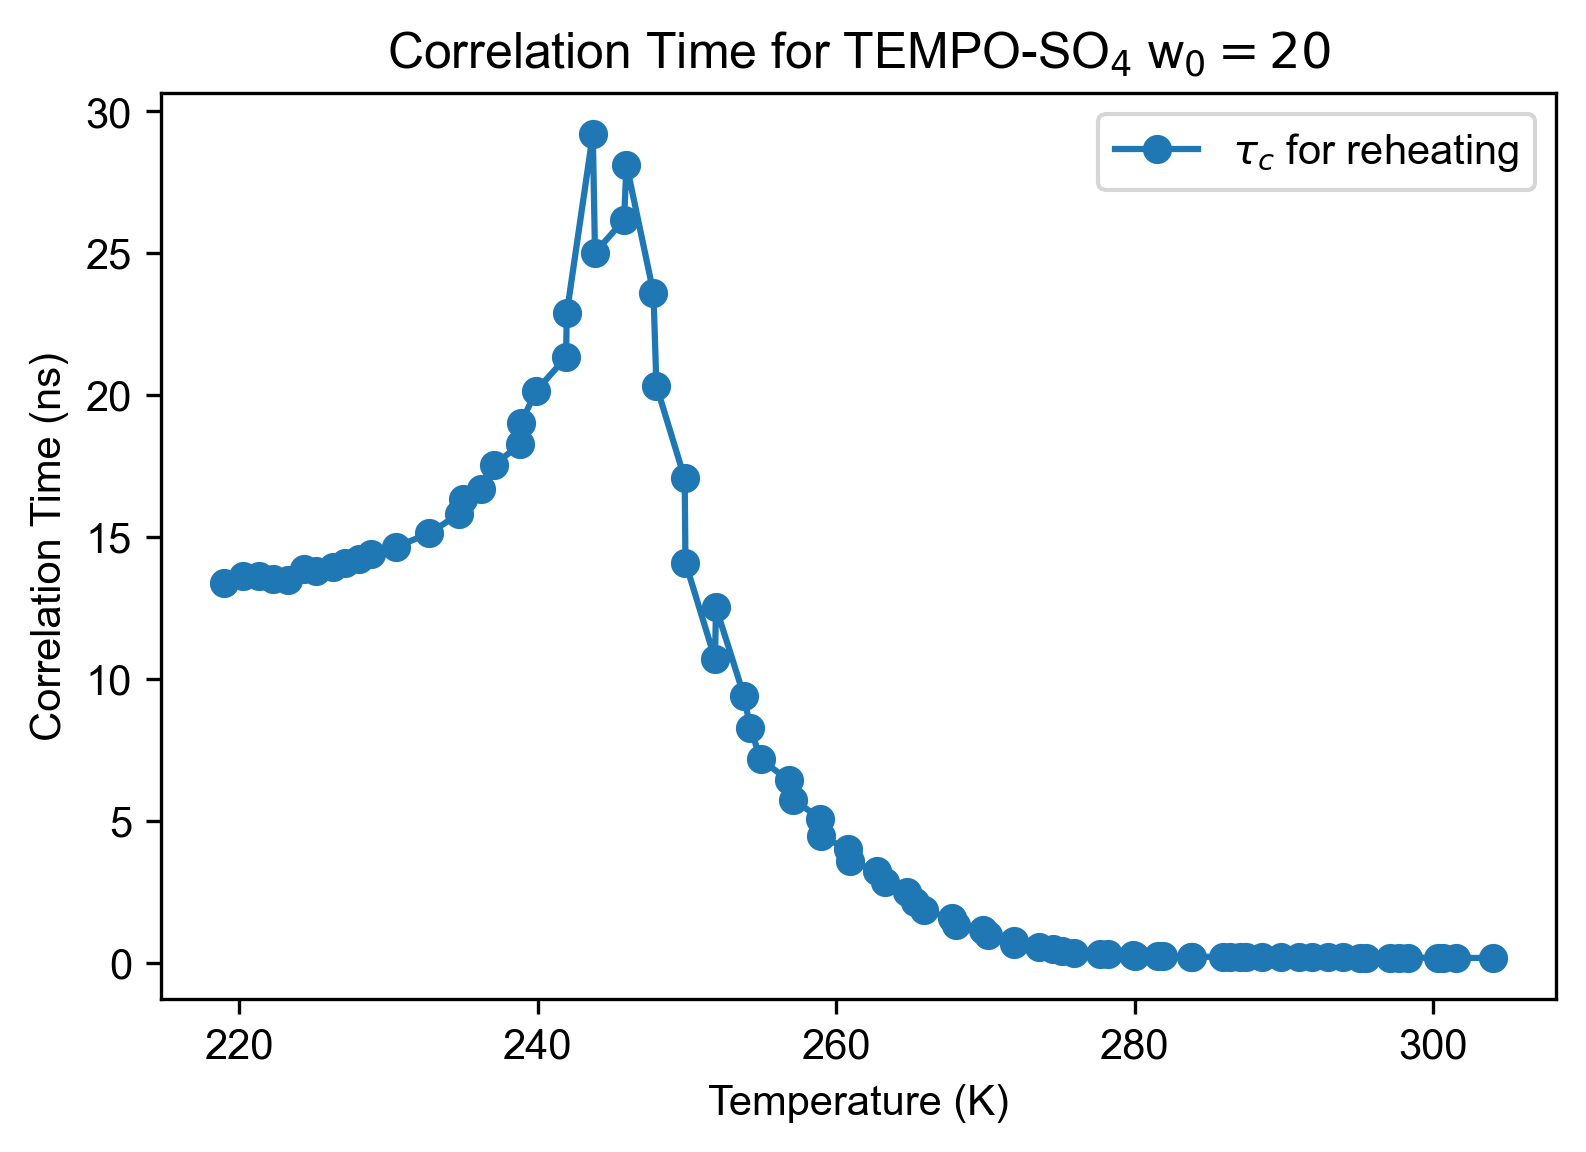

In [166]:
# Tau caculation
figure(dpi=300, figsize=(6,4))
plot(temp_reheating, tau_reheating/1e-9, linestyle='-',  marker='o', label=r"$\tau_c$ for reheating")
legend()
# xlim(253,335)
xlabel('Temperature (K)')
ylabel('Correlation Time (ns)')
title('Correlation Time for TEMPO-SO$_4$ w$_0=20$')
show()

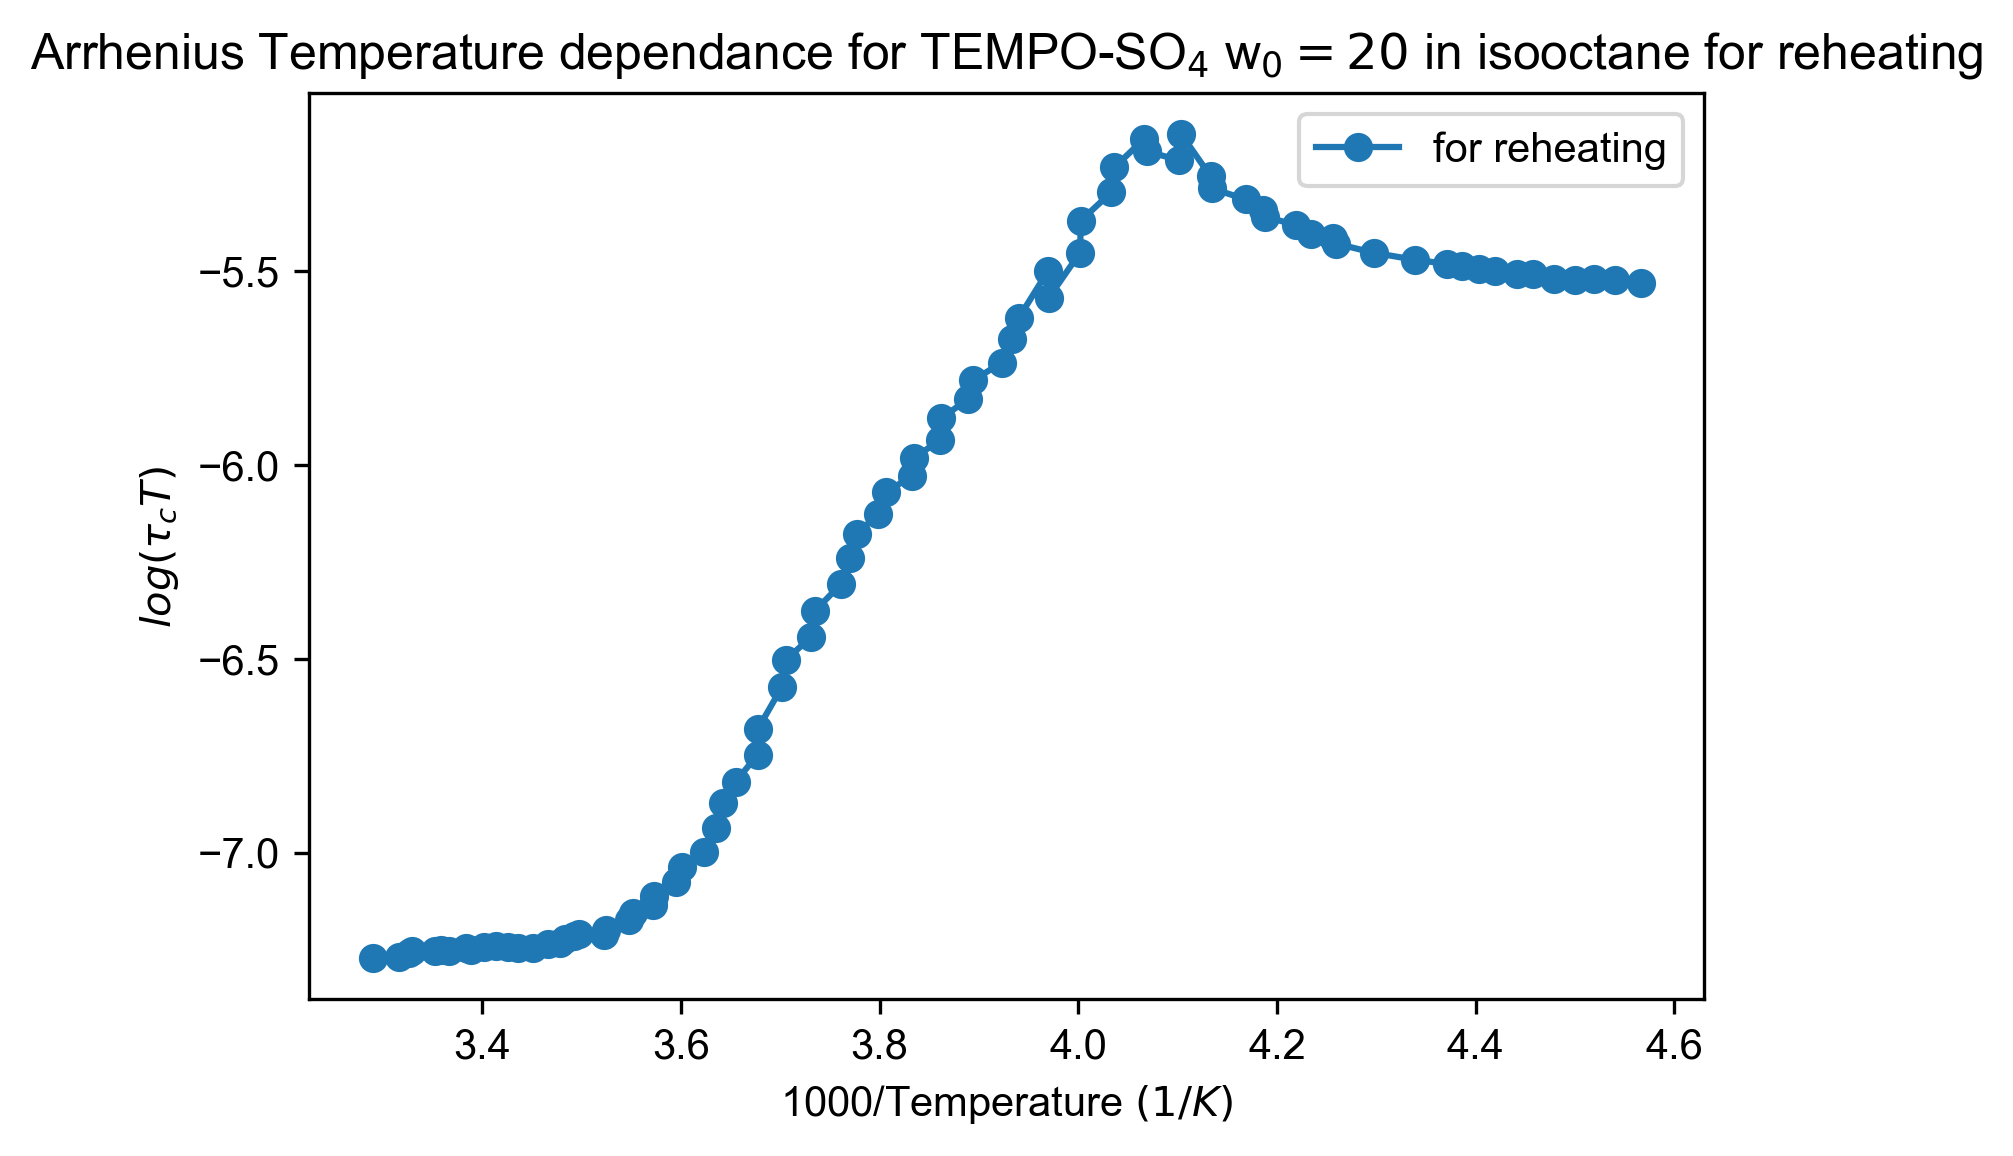

In [167]:
# Arrhenius  
figure(dpi=300, figsize=(6,4))
plot(1000/temp_reheating, log10(tau_reheating*temp_reheating), linestyle='-',  marker='o', label=r"for reheating")
legend()
xlabel(r"1000/Temperature $(1/K)$")
ylabel(r"$log(\tau_cT)$")
title('Arrhenius Temperature dependance for TEMPO-SO$_4$ w$_0=20$ in isooctane for reheating')
show()

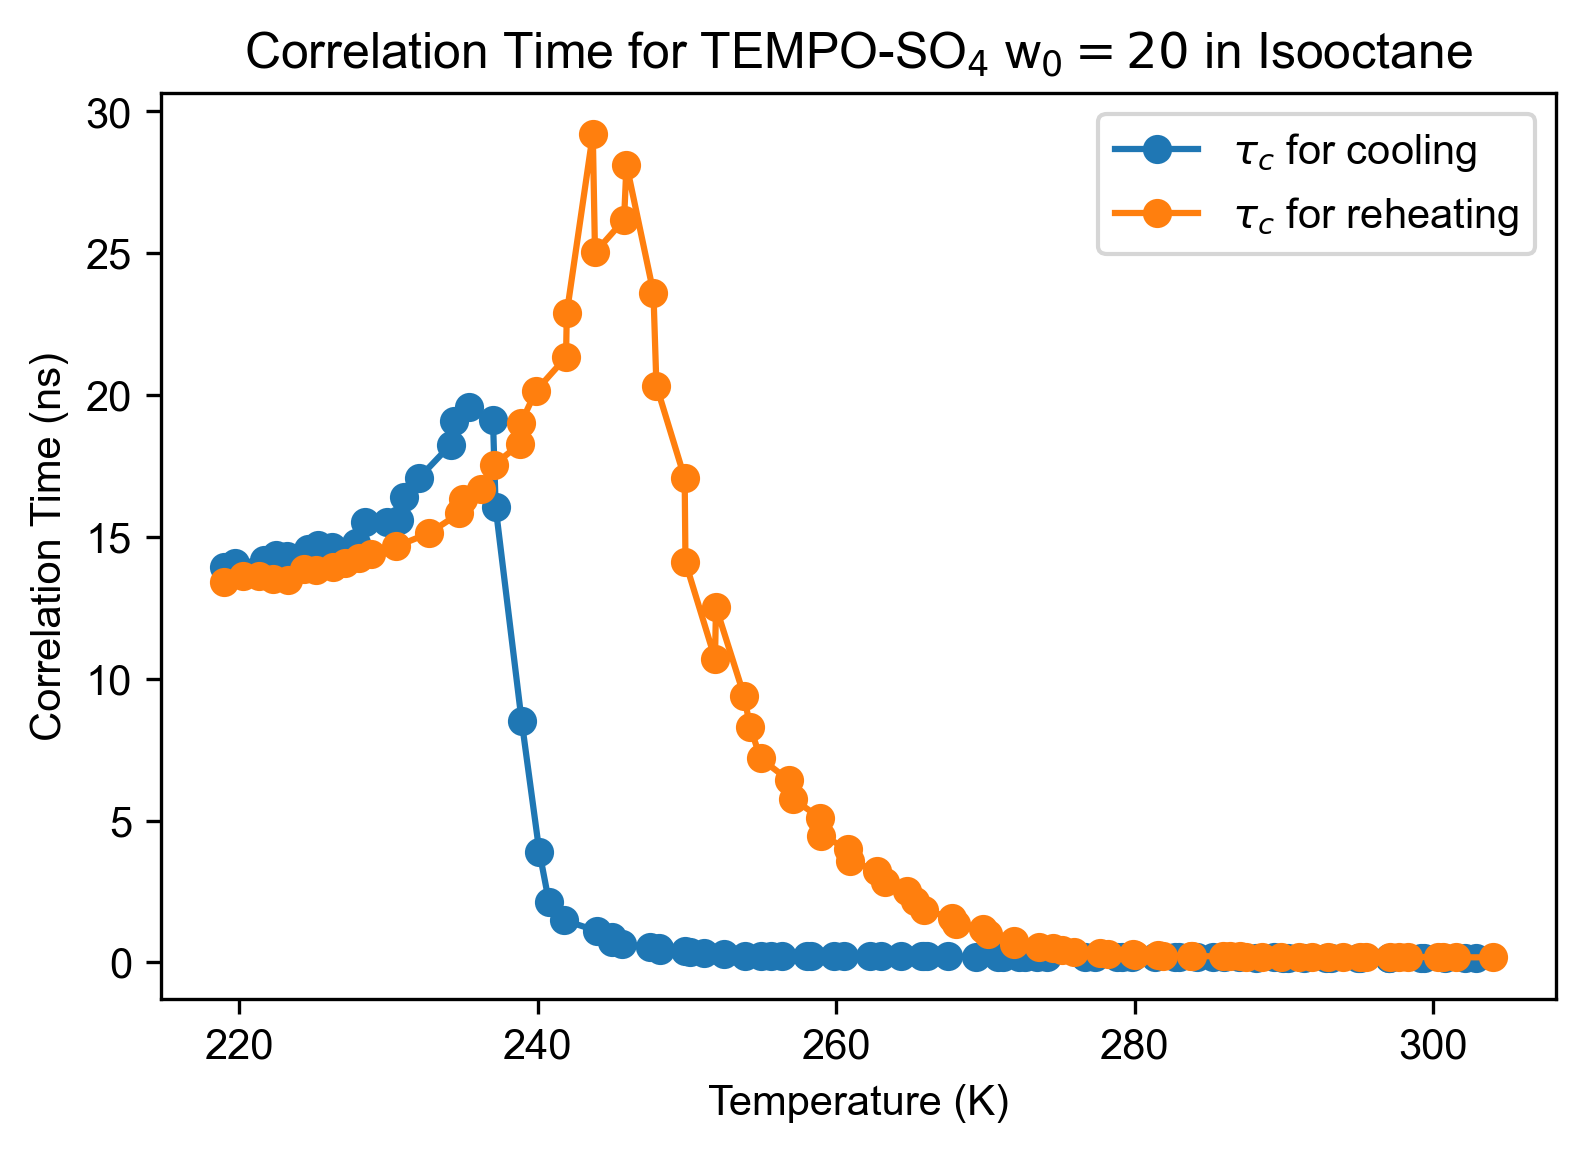

In [168]:
# Tau caculation
figure(dpi=300, figsize=(6,4))
plot(temp_cooling, tau_cooling/1e-9, linestyle='-',  marker='o', label=r"$\tau_c$ for cooling")
plot(temp_reheating, tau_reheating/1e-9, linestyle='-',  marker='o', label=r"$\tau_c$ for reheating")
legend()
# xlim(250,335)
xlabel('Temperature (K)')
ylabel('Correlation Time (ns)')
title('Correlation Time for TEMPO-SO$_4$ w$_0=20$ in Isooctane')
show()

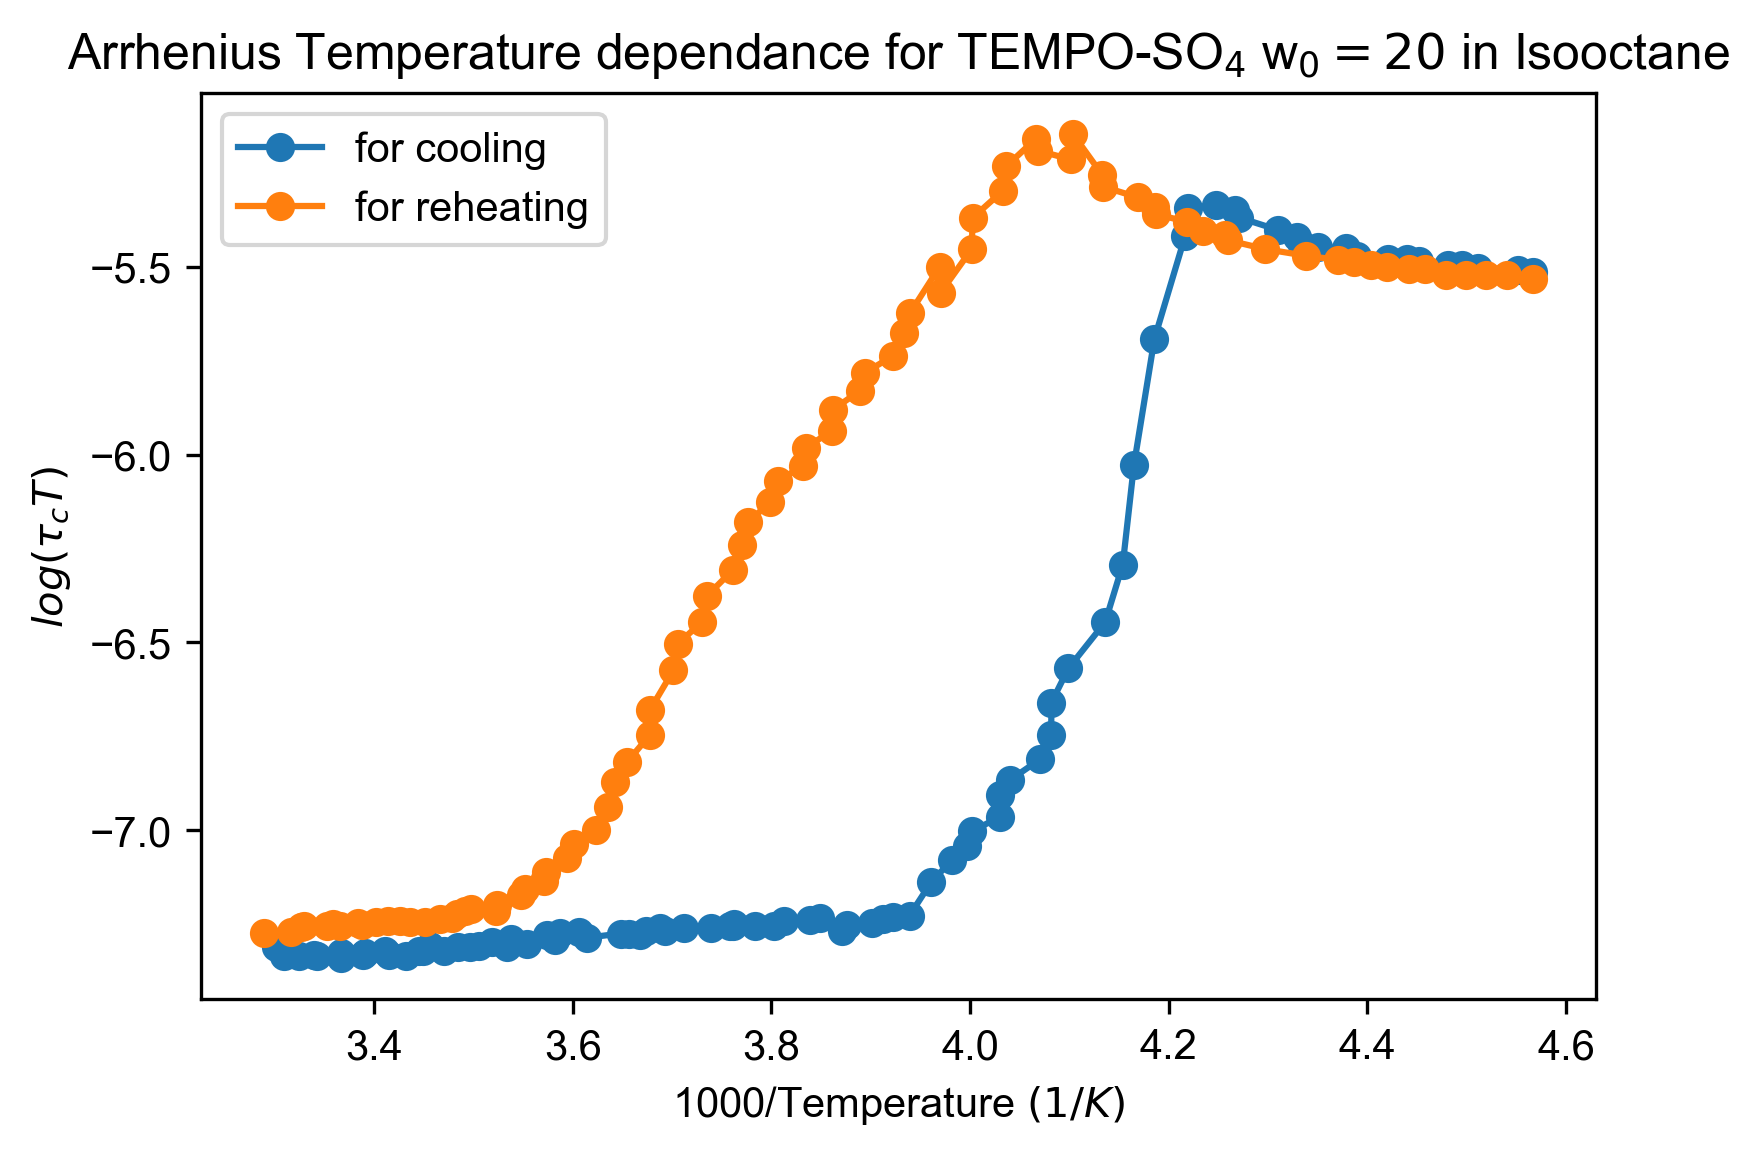

In [169]:
# Arrhenius  
figure(dpi=300, figsize=(6,4))
plot(1000/temp_cooling, log10(tau_cooling*temp_cooling), linestyle='-',  marker='o', label=r"for cooling")
plot(1000/temp_reheating, log10(tau_reheating*temp_reheating), linestyle='-',  marker='o', label=r"for reheating")
legend()
# xlim(2.9,4.1)
xlabel(r"1000/Temperature $(1/K)$")
ylabel(r"$log(\tau_cT)$")
title('Arrhenius Temperature dependance for TEMPO-SO$_4$ w$_0=20$ in Isooctane')
show()

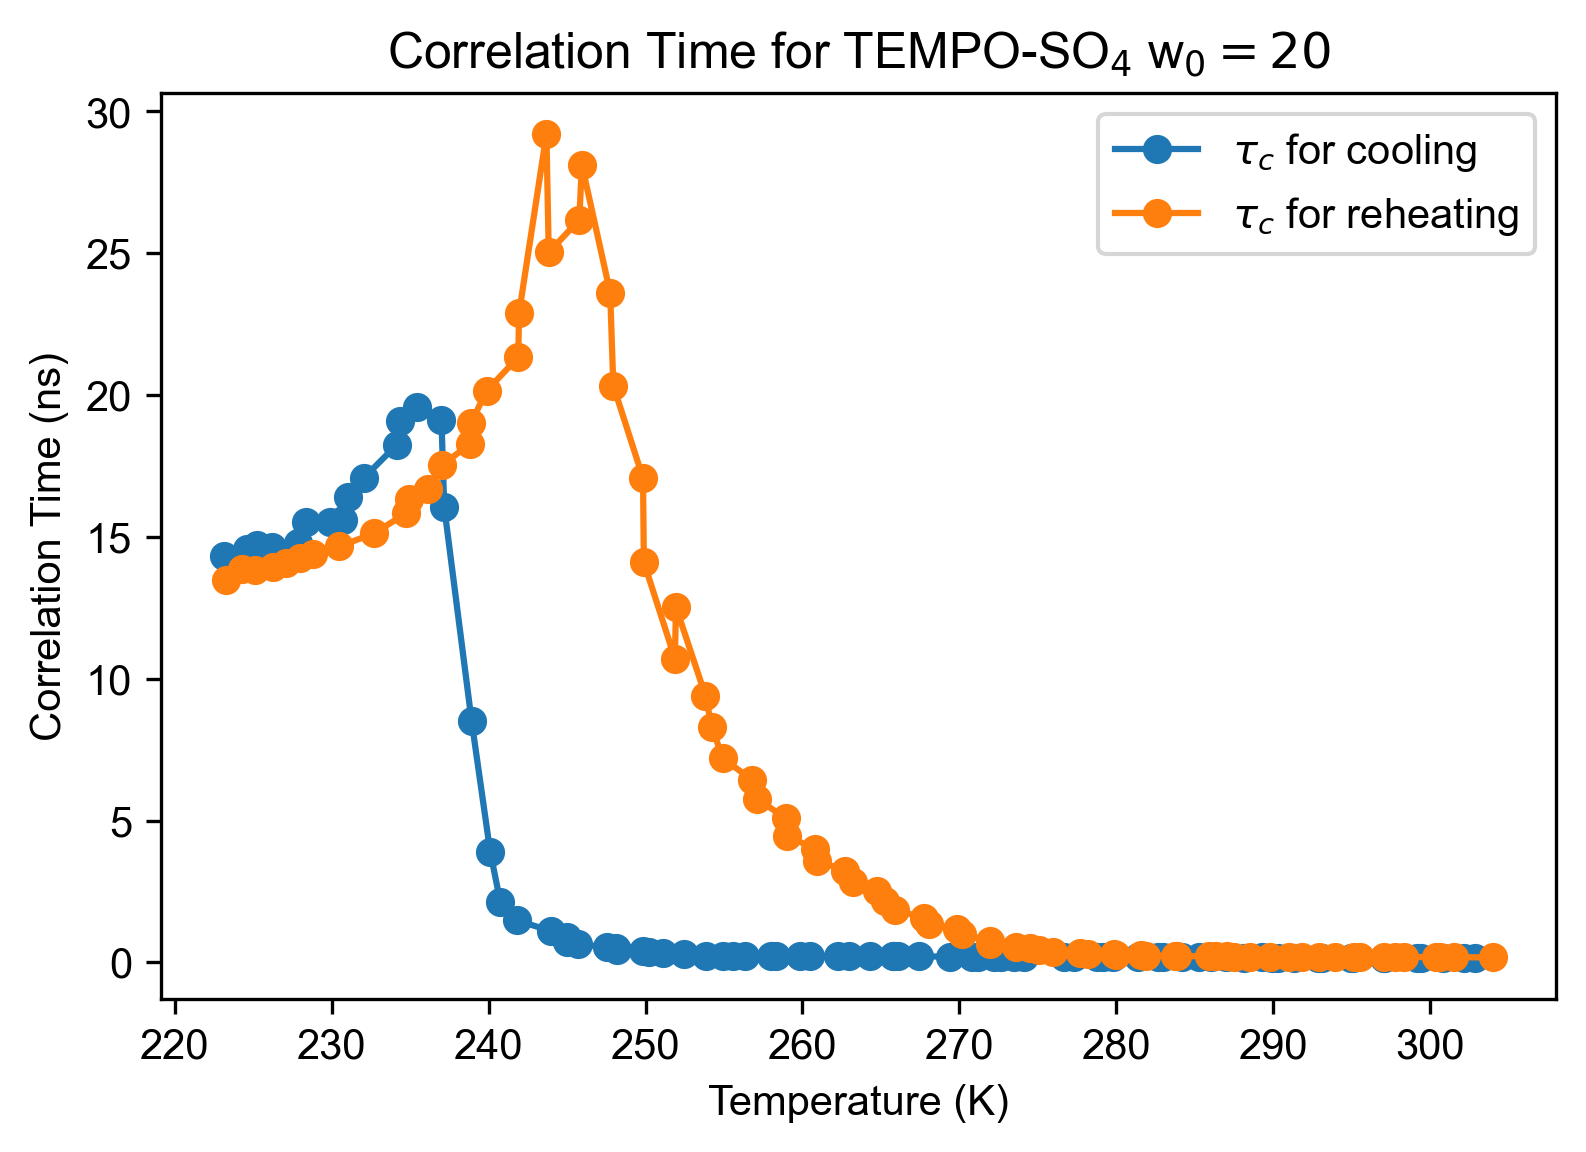

In [170]:
# Tau caculation
figure(dpi=300, figsize=(6,4))
plot(temp_cooling[4:], tau_cooling[4:]/1e-9, linestyle='-',  marker='o', label=r"$\tau_c$ for cooling")
plot(temp_reheating[4:], tau_reheating[4:]/1e-9, linestyle='-',  marker='o', label=r"$\tau_c$ for reheating")
legend()
xlabel('Temperature (K)')
ylabel('Correlation Time (ns)')
title('Correlation Time for TEMPO-SO$_4$ w$_0=20$')
show()

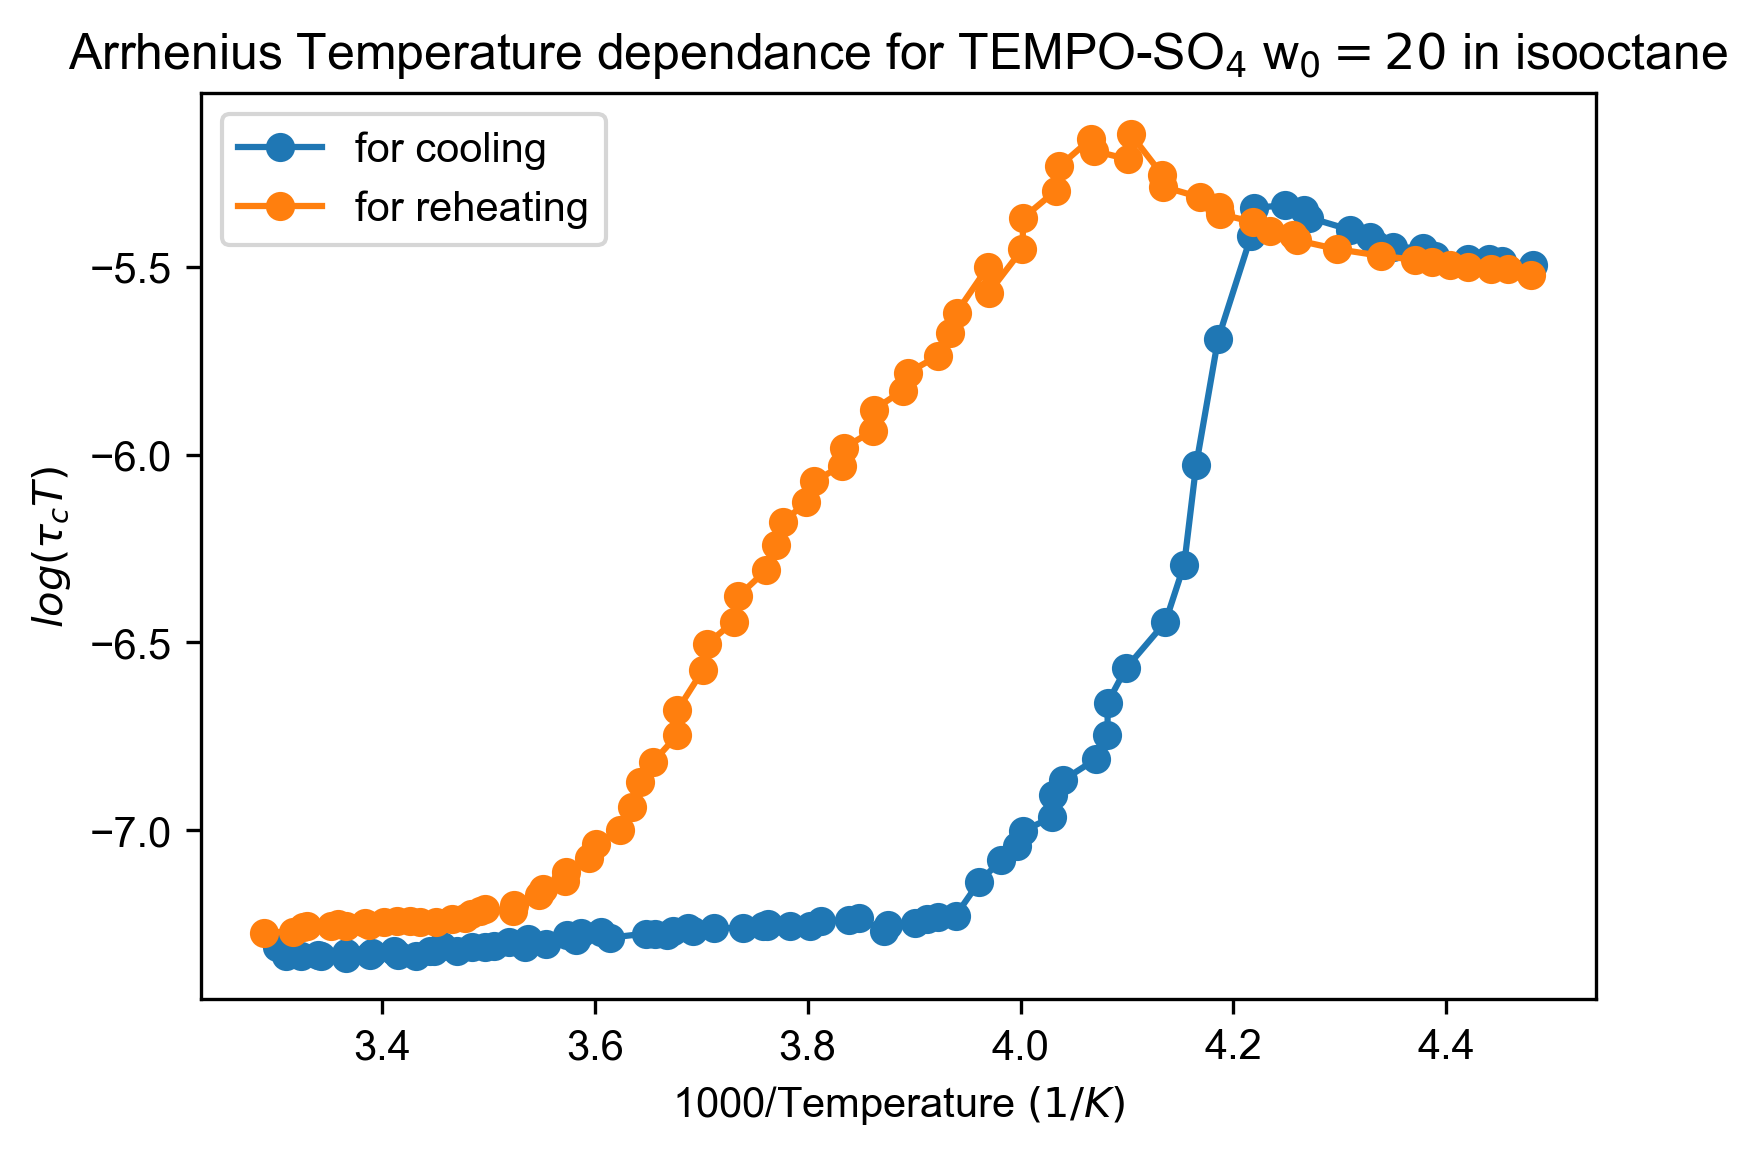

In [171]:
# Arrhenius  
figure(dpi=300, figsize=(6,4))
plot(1000/temp_cooling[4:], log10(tau_cooling[4:]*temp_cooling[4:]), linestyle='-',  marker='o', label=r"for cooling")
plot(1000/temp_reheating[4:], log10(tau_reheating[4:]*temp_reheating[4:]), linestyle='-',  marker='o', label=r"for reheating")
legend()
# xlim(3,4)
xlabel(r"1000/Temperature $(1/K)$")
ylabel(r"$log(\tau_cT)$")
title('Arrhenius Temperature dependance for TEMPO-SO$_4$ w$_0=20$ in isooctane')
show()